# 3.6. Thực nghiệm và đánh giá mô hình FinIntel

Notebook tái chạy toàn bộ quy trình huấn luyện, hiệu chỉnh xác suất, đánh giá phân cụm/bất thường,
đánh giá mô hình dự báo nguy cơ kiệt quệ tài chính và giải thích mô hình bằng TreeSHAP
trên bản sao thực nghiệm 375 doanh nghiệp trong `data/go_live_nfr_run`.

Kết quả phân biệt rõ ba tập theo thời gian: **Train** (huấn luyện), **Validation** (hiệu chỉnh xác suất
Platt OOF và đóng băng ngưỡng F2 — không dùng để tuyên bố hiệu năng ngoài mẫu), và **Test**
(kiểm thử ngoài mẫu `OUT_OF_SAMPLE_TEST`). Toàn bộ bảng và biểu đồ được xuất ra `notebooks/outputs/3_6/`.


In [ ]:
from pathlib import Path
from datetime import date, datetime, timezone
import hashlib, html, json, math, sys
import numpy as np
import polars as pl
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    fbeta_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)


def find_project():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "src/finintel").is_dir() and (
            candidate / "pyproject.toml"
        ).is_file():
            return candidate
    raise RuntimeError("Mở notebook bên trong thư mục dự án FinIntel.")


ROOT = find_project()
sys.path.insert(0, str(ROOT / "src"))
from finintel.storage.schemas import canonicalize_financial_facts
from finintel.quality.gate import evaluate_quality_gate
from finintel.analytics.intermediates import prepare_periods
from finintel.analytics.ratios import calculate_ratios
from finintel.ml.classical_scores import add_classical_scores
from finintel.ml.supervised.temporal_split import build_pit_ml_splits
from finintel.ml.unsupervised import FinancialArchetypes, UNSUPERVISED_FEATURE_SET
from finintel.ml.supervised.train import (
    BASE_FEATURES,
    SECTOR_ADJUSTED_FEATURES,
    _prepare_eval_fold,
    _score_three_models,
    _sigmoid,
    build_evaluation_report,
    train_distress_model,
)
from finintel.ml.supervised.explain import (
    _FEATURE_DISPLAY_NAME_VN,
    compute_shap_contributions,
)

DATA_ROOT = ROOT / "data/go_live_nfr_run"
FACTS_PATH = (
    DATA_ROOT
    / "curated/financial_facts/b6_norm_full_nfr_after_20261120T155606Z/financial_facts.parquet"
)
ISSUERS_PATH = DATA_ROOT / "curated/issuers.parquet"
MANIFEST_PATH = (
    DATA_ROOT
    / "metadata/ml_runs/e221ee76-98a1-4510-92ba-cb6a950e36f9/ml_run_manifest.json"
)
SAVED_REPORT_PATH = (
    DATA_ROOT
    / "metadata/ml_runs/e221ee76-98a1-4510-92ba-cb6a950e36f9/evaluation_report.json"
)

for path in (FACTS_PATH, ISSUERS_PATH, MANIFEST_PATH, SAVED_REPORT_PATH):
    if not path.is_file():
        raise FileNotFoundError(f"Thiếu đầu vào thực nghiệm: {path}")

RUN_MANIFEST = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
SAVED_REPORT = json.loads(SAVED_REPORT_PATH.read_text(encoding="utf-8"))
AS_OF = date.fromisoformat(RUN_MANIFEST["as_of"])
VALIDATION_START = date.fromisoformat(RUN_MANIFEST["validation_start"])
TEST_START = date.fromisoformat(RUN_MANIFEST["test_start"])
SCOPE = RUN_MANIFEST["statement_scope"]
FEATURES = (
    SECTOR_ADJUSTED_FEATURES
    if RUN_MANIFEST["feature_set"] == "sector_adjusted"
    else BASE_FEATURES
)
SOURCE_NOTE = f"Nguồn: bản sao thực nghiệm FinIntel, mốc thông tin {AS_OF:%d/%m/%Y}."
COLORS = ["#245A81", "#168B83", "#E4A33A", "#C05252", "#7C65A9"]

CSS = """<style>
.fi-card{background:white;color:#172B3A;font-family:Arial,sans-serif;padding:30px 36px;max-width:1380px;border:1px solid #d9e2eb;box-sizing:border-box;}
.fi-card h2{font-size:26px;line-height:1.3;margin:0 0 14px;color:#153c5a;}
.fi-card table{border-collapse:collapse;width:100%;font-size:17px;line-height:1.42;}
.fi-card th{background:#eaf0f6;text-align:left;border-bottom:2px solid #a7bbce;padding:10px;}
.fi-card td{border-bottom:1px solid #e1e7ed;padding:9px 10px;overflow-wrap:anywhere;}
.fi-card tr:nth-child(even) td{background:#f7f9fc;}
.fi-card .caption{font-size:17px;line-height:1.5;margin:16px 0 8px;}
.fi-card .source{font-size:13px;color:#586a7c;margin-top:14px;}
</style>"""


def fmt(value):
    if value is None:
        return "NULL"
    if isinstance(value, (date, datetime)):
        return value.strftime("%d/%m/%Y")
    if isinstance(value, (bool, np.bool_)):
        return "Có" if value else "Không"
    if isinstance(value, (int, np.integer)):
        return f"{int(value):,}".replace(",", ".")
    if isinstance(value, (float, np.floating)):
        if not math.isfinite(float(value)):
            return str(value)
        return (
            f"{float(value):,.4f}".replace(",", "_").replace(".", ",").replace("_", ".")
        )
    if isinstance(value, (list, tuple)):
        return ", ".join(map(str, value))
    return str(value)


def publish(payload):
    if "_CAPTURE" in globals():
        _CAPTURE(payload)
    else:
        from IPython.display import HTML, display

        if payload["kind"] == "table":
            display(HTML(payload["html"]))
        else:
            fig = go.Figure(payload["figure"])
            display(HTML(fig.to_html(include_plotlyjs=True, full_html=False)))


def show_table(title, frame, caption="", limit=25):
    df = frame if isinstance(frame, pl.DataFrame) else pl.DataFrame(frame)
    visible = df.head(limit)
    head = "".join(f"<th>{html.escape(x)}</th>" for x in visible.columns)
    rows = "".join(
        "<tr>" + "".join(f"<td>{html.escape(fmt(v))}</td>" for v in row) + "</tr>"
        for row in visible.iter_rows()
    )
    extra = f" Hiển thị {visible.height}/{df.height} dòng." if df.height > limit else ""
    card = (
        CSS
        + f'<div class="fi-card"><h2>{html.escape(title)}</h2><table><thead><tr>{head}</tr></thead><tbody>{rows}</tbody></table><p class="caption">{html.escape(caption + extra)}</p><div class="source">{html.escape(SOURCE_NOTE)}</div></div>'
    )
    publish({"kind": "table", "title": title, "html": card, "caption": caption + extra})


def show_figure(
    title, fig, caption="", height=620, width=1200, left_margin=None, bottom_margin=125
):
    if left_margin is None:
        left_margin = (
            290 if any(getattr(t, "orientation", None) == "h" for t in fig.data) else 90
        )
    fig.update_layout(
        template="plotly_white",
        width=width,
        height=height,
        font=dict(family="Arial", size=16, color="#172B3A"),
        title=dict(text=title, x=0.03, font=dict(size=23)),
        margin=dict(l=left_margin, r=60, t=95, b=bottom_margin),
        legend=dict(orientation="h", y=-0.16, x=0.0),
        paper_bgcolor="white",
        plot_bgcolor="white",
    )
    publish(
        {
            "kind": "figure",
            "title": title,
            "figure": json.loads(fig.to_json()),
            "caption": caption,
        }
    )


SOURCE_HASHES = {
    str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
    for p in (FACTS_PATH, ISSUERS_PATH, MANIFEST_PATH)
}
facts = canonicalize_financial_facts(pl.read_parquet(FACTS_PATH))
issuers = pl.read_parquet(ISSUERS_PATH)
qg = evaluate_quality_gate(
    facts, issuers=issuers, checked_at=datetime(2026, 11, 20, tzinfo=timezone.utc)
)
periods = prepare_periods(qg.clean_facts, issuers, as_of=AS_OF, include_ml_inputs=True)
ratios = calculate_ratios(periods)
classical = add_classical_scores(ratios)
splits = build_pit_ml_splits(
    qg.clean_facts,
    issuers,
    validation_start=VALIDATION_START,
    test_start=TEST_START,
    as_of=AS_OF,
    require_exact_filing=True,
    statement_scope=SCOPE,
    taxonomy_version=RUN_MANIFEST["taxonomy_version"],
    target_mode=RUN_MANIFEST["target_mode"],
    precomputed_as_of_scored=classical,
)
eval_folds = {
    name: _prepare_eval_fold(frame, target="distress_target")
    for name, frame in splits.items()
}


## 3.6.1. Thiết lập thực nghiệm và mô hình đối chứng

Thiết lập thực nghiệm sử dụng dữ liệu báo cáo tài chính hợp nhất (`CONSOLIDATED`) của 375 doanh nghiệp phi tài chính,
tuân thủ chặt chẽ mốc thông tin Point-in-Time (`EXACT_FILING`) để loại bỏ rò rỉ dữ liệu tương lai.
Ba mô hình có giám sát (Altman Z'', Logistic Regression L2 và XGBoost hiệu chỉnh Platt) được đánh giá trên
cùng một tập mẫu khởi phát mới (`~already_distressed_at_t` và có giá trị Altman hữu hạn).


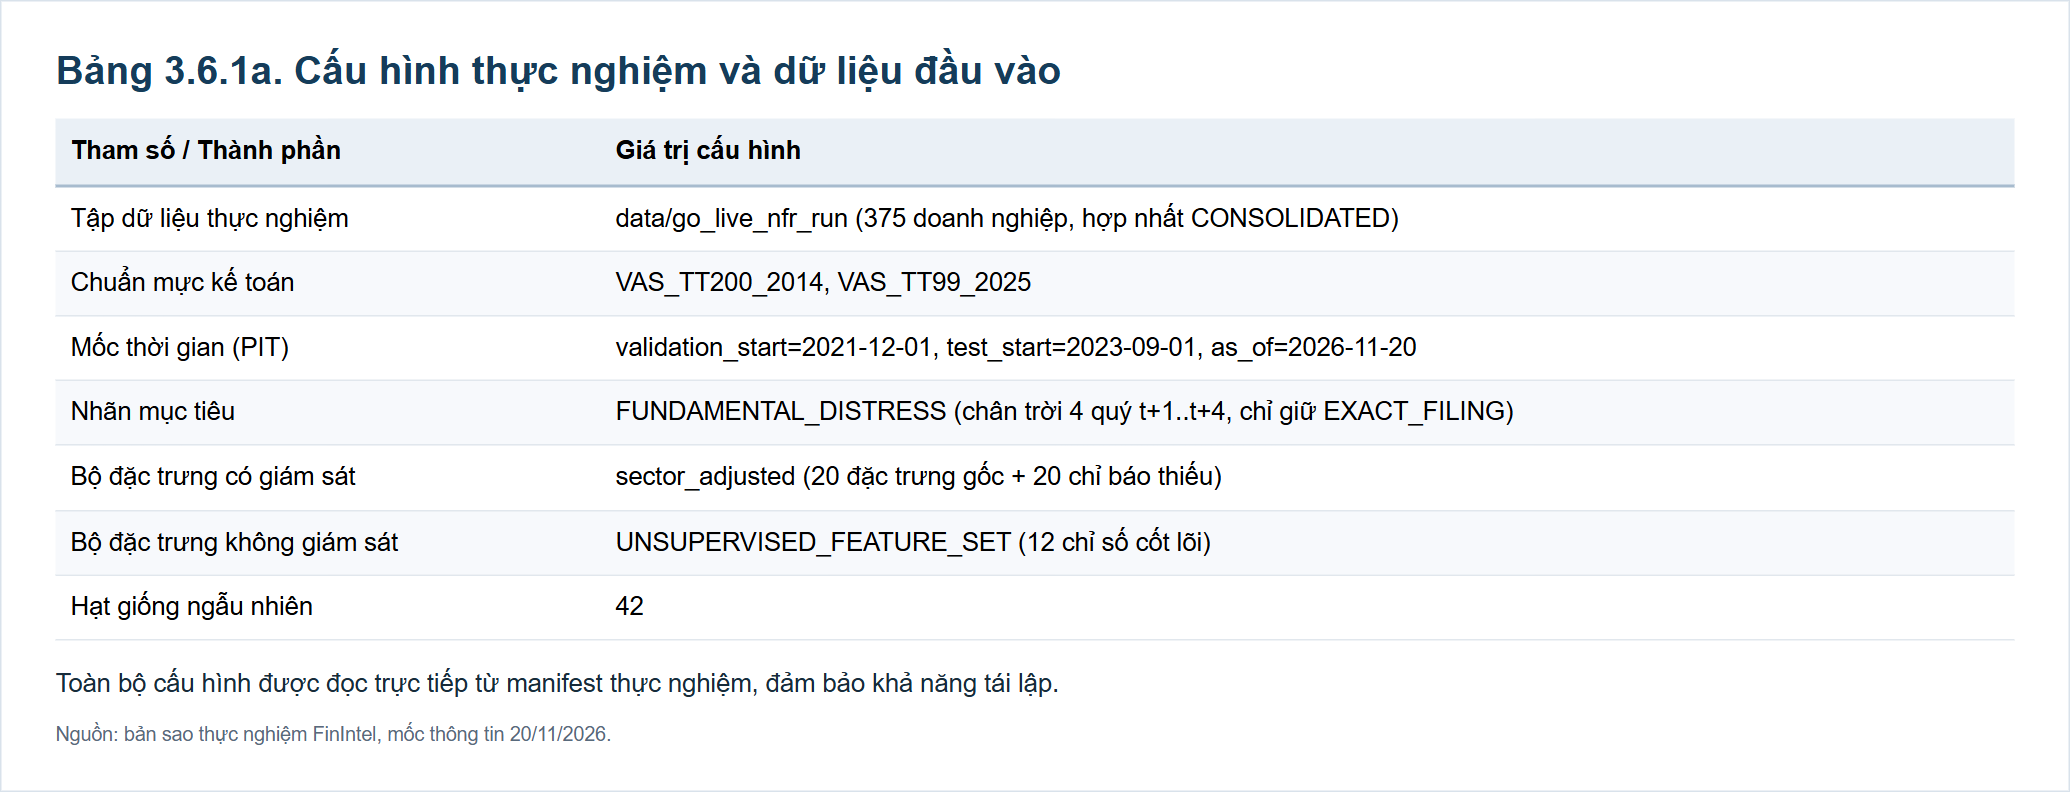

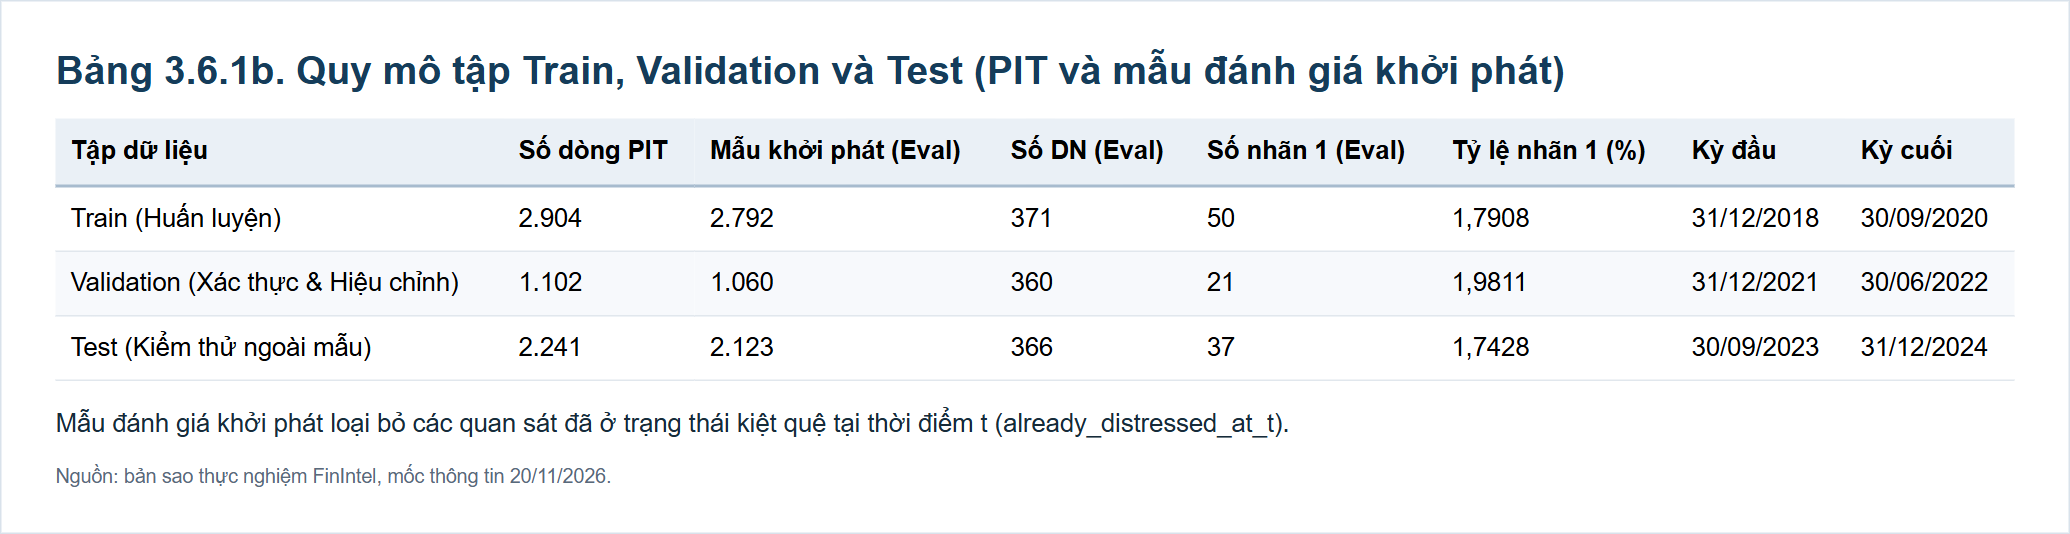

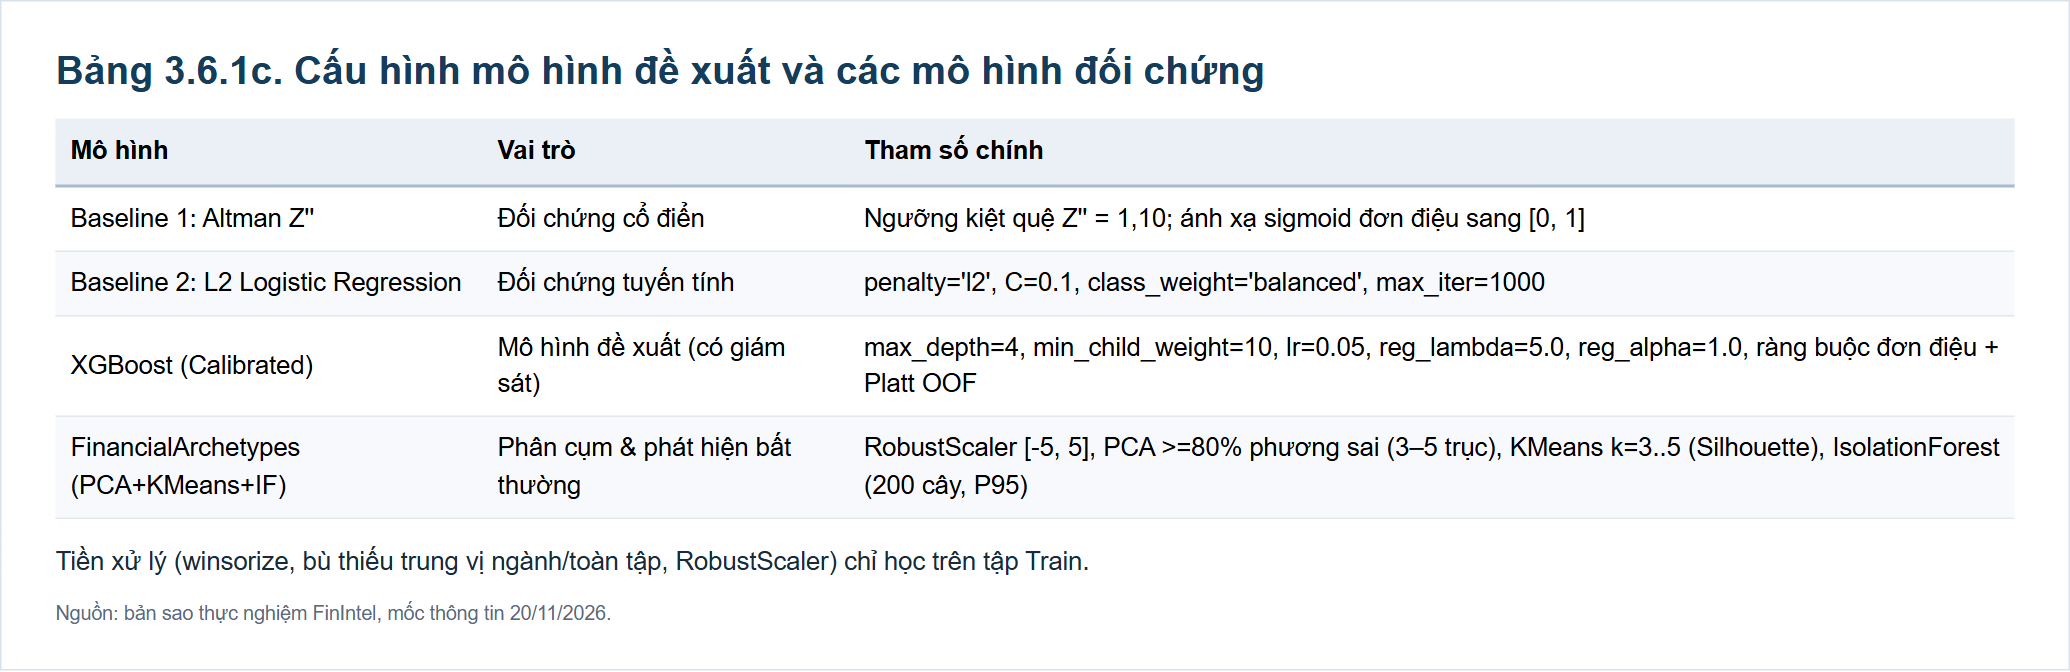

In [ ]:
setup_rows = [
    {
        "Tham số / Thành phần": "Tập dữ liệu thực nghiệm",
        "Giá trị cấu hình": "data/go_live_nfr_run (375 doanh nghiệp, hợp nhất CONSOLIDATED)",
    },
    {
        "Tham số / Thành phần": "Chuẩn mực kế toán",
        "Giá trị cấu hình": ", ".join(RUN_MANIFEST["scored_taxonomies"]),
    },
    {
        "Tham số / Thành phần": "Mốc thời gian (PIT)",
        "Giá trị cấu hình": f"validation_start={VALIDATION_START}, test_start={TEST_START}, as_of={AS_OF}",
    },
    {
        "Tham số / Thành phần": "Nhãn mục tiêu",
        "Giá trị cấu hình": f"{RUN_MANIFEST['target_mode']} (chân trời 4 quý t+1..t+4, chỉ giữ EXACT_FILING)",
    },
    {
        "Tham số / Thành phần": "Bộ đặc trưng có giám sát",
        "Giá trị cấu hình": f"{RUN_MANIFEST['feature_set']} ({len(FEATURES)} đặc trưng gốc + {len(FEATURES)} chỉ báo thiếu)",
    },
    {
        "Tham số / Thành phần": "Bộ đặc trưng không giám sát",
        "Giá trị cấu hình": f"UNSUPERVISED_FEATURE_SET ({len(UNSUPERVISED_FEATURE_SET)} chỉ số cốt lõi)",
    },
    {
        "Tham số / Thành phần": "Hạt giống ngẫu nhiên",
        "Giá trị cấu hình": str(RUN_MANIFEST["random_seed"]),
    },
]
show_table(
    "Bảng 3.6.1a. Cấu hình thực nghiệm và dữ liệu đầu vào",
    setup_rows,
    "Toàn bộ cấu hình được đọc trực tiếp từ manifest thực nghiệm, đảm bảo khả năng tái lập.",
)

split_table = []
for name, label in [
    ("train", "Train (Huấn luyện)"),
    ("validation", "Validation (Xác thực & Hiệu chỉnh)"),
    ("test", "Test (Kiểm thử ngoài mẫu)"),
]:
    pit_df = splits[name]
    ev_df = eval_folds[name]
    pos_ev = ev_df.filter(pl.col("distress_target") == 1).height
    split_table.append(
        {
            "Tập dữ liệu": label,
            "Số dòng PIT": pit_df.height,
            "Mẫu khởi phát (Eval)": ev_df.height,
            "Số DN (Eval)": ev_df["issuer_id"].n_unique(),
            "Số nhãn 1 (Eval)": pos_ev,
            "Tỷ lệ nhãn 1 (%)": 100.0 * pos_ev / ev_df.height if ev_df.height else 0.0,
            "Kỳ đầu": ev_df["period_end_date"].min(),
            "Kỳ cuối": ev_df["period_end_date"].max(),
        }
    )
show_table(
    "Bảng 3.6.1b. Quy mô tập Train, Validation và Test (PIT và mẫu đánh giá khởi phát)",
    split_table,
    "Mẫu đánh giá khởi phát loại bỏ các quan sát đã ở trạng thái kiệt quệ tại thời điểm t (already_distressed_at_t).",
)

models_cfg = [
    {
        "Mô hình": "Baseline 1: Altman Z''",
        "Vai trò": "Đối chứng cổ điển",
        "Tham số chính": "Ngưỡng kiệt quệ Z'' = 1,10; ánh xạ sigmoid đơn điệu sang [0, 1]",
    },
    {
        "Mô hình": "Baseline 2: L2 Logistic Regression",
        "Vai trò": "Đối chứng tuyến tính",
        "Tham số chính": "penalty='l2', C=0.1, class_weight='balanced', max_iter=1000",
    },
    {
        "Mô hình": "XGBoost (Calibrated)",
        "Vai trò": "Mô hình đề xuất (có giám sát)",
        "Tham số chính": "max_depth=4, min_child_weight=10, lr=0.05, reg_lambda=5.0, reg_alpha=1.0, ràng buộc đơn điệu + Platt OOF",
    },
    {
        "Mô hình": "FinancialArchetypes (PCA+KMeans+IF)",
        "Vai trò": "Phân cụm & phát hiện bất thường",
        "Tham số chính": "RobustScaler [-5, 5], PCA >=80% phương sai (3–5 trục), KMeans k=3..5 (Silhouette), IsolationForest (200 cây, P95)",
    },
]
show_table(
    "Bảng 3.6.1c. Cấu hình mô hình đề xuất và các mô hình đối chứng",
    models_cfg,
    "Tiền xử lý (winsorize, bù thiếu trung vị ngành/toàn tập, RobustScaler) chỉ học trên tập Train.",
)


## 3.6.2. Phương pháp và chỉ số đánh giá

Do tỷ lệ kiệt quệ tài chính chỉ khoảng 1,7%–2,0% (mất cân bằng lớp mạnh), việc đánh giá tách bạch ba khía cạnh:
(1) **Khả năng phân biệt thứ hạng** (ROC-AUC, PR-AUC, Recall@Top 10%, F2-Score);
(2) **Độ tin cậy xác suất** (Brier Score, biểu đồ hiệu chỉnh Reliability Diagram);
(3) **Khả năng giải thích** (TreeSHAP cộng tính chính xác trên log-odds).


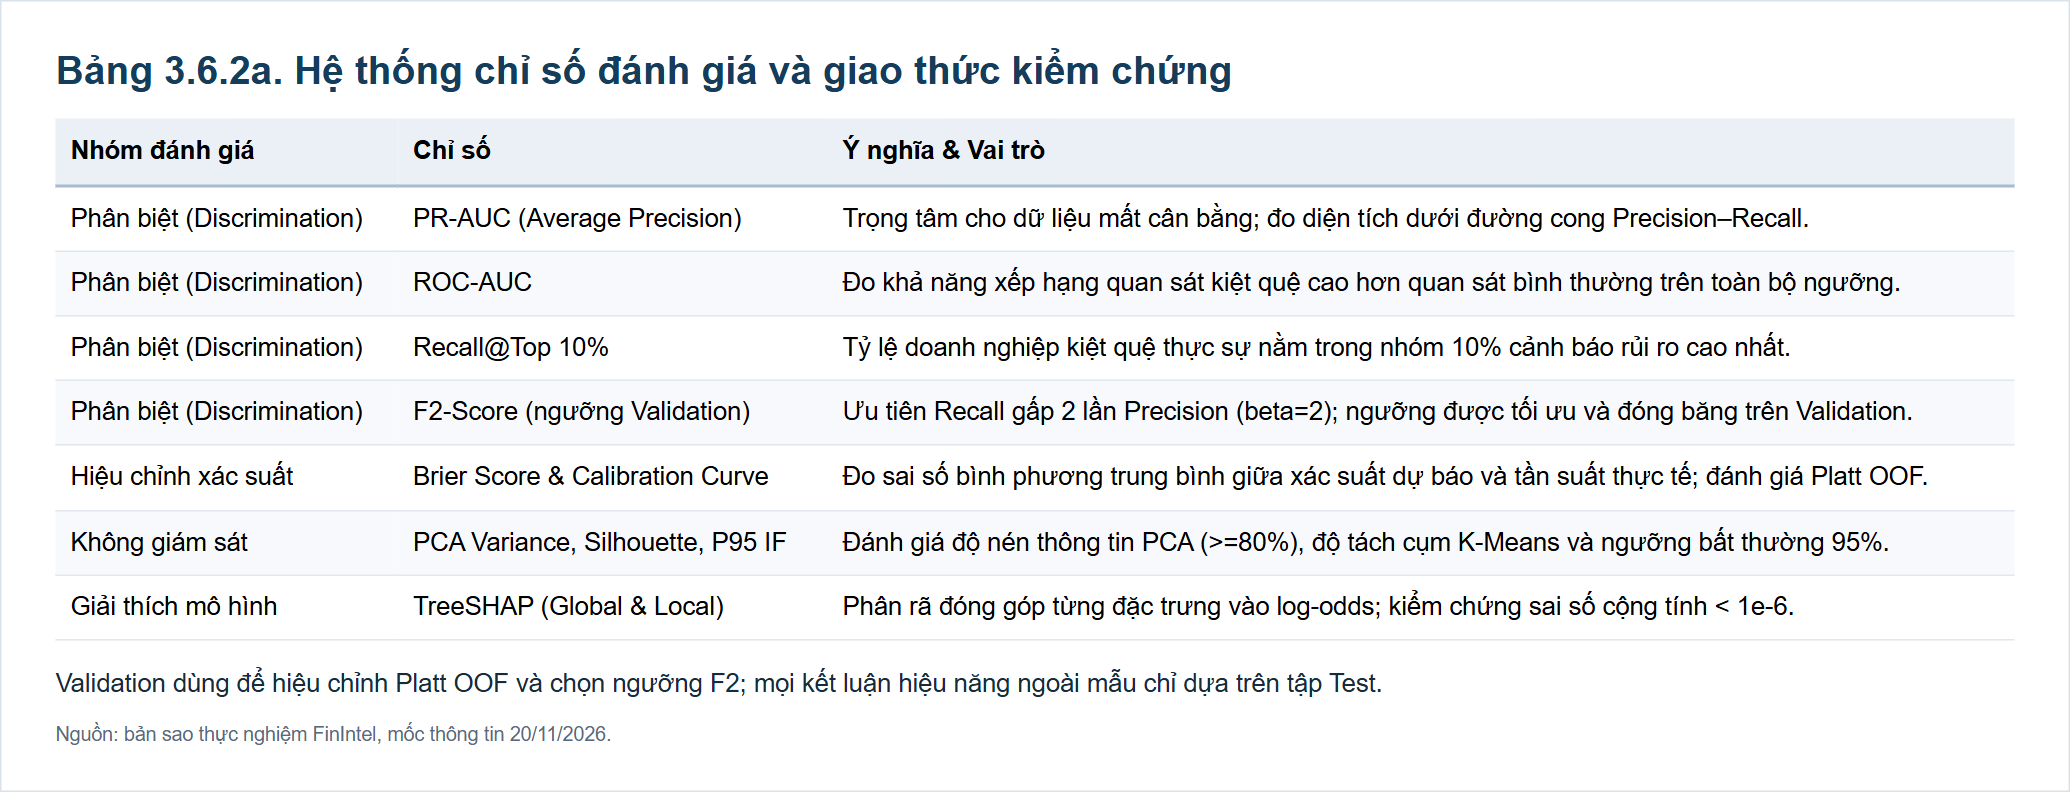

In [ ]:
metrics_spec = [
    {
        "Nhóm đánh giá": "Phân biệt (Discrimination)",
        "Chỉ số": "PR-AUC (Average Precision)",
        "Ý nghĩa & Vai trò": "Trọng tâm cho dữ liệu mất cân bằng; đo diện tích dưới đường cong Precision–Recall.",
    },
    {
        "Nhóm đánh giá": "Phân biệt (Discrimination)",
        "Chỉ số": "ROC-AUC",
        "Ý nghĩa & Vai trò": "Đo khả năng xếp hạng quan sát kiệt quệ cao hơn quan sát bình thường trên toàn bộ ngưỡng.",
    },
    {
        "Nhóm đánh giá": "Phân biệt (Discrimination)",
        "Chỉ số": "Recall@Top 10%",
        "Ý nghĩa & Vai trò": "Tỷ lệ doanh nghiệp kiệt quệ thực sự nằm trong nhóm 10% cảnh báo rủi ro cao nhất.",
    },
    {
        "Nhóm đánh giá": "Phân biệt (Discrimination)",
        "Chỉ số": "F2-Score (ngưỡng Validation)",
        "Ý nghĩa & Vai trò": "Ưu tiên Recall gấp 2 lần Precision (beta=2); ngưỡng được tối ưu và đóng băng trên Validation.",
    },
    {
        "Nhóm đánh giá": "Hiệu chỉnh xác suất",
        "Chỉ số": "Brier Score & Calibration Curve",
        "Ý nghĩa & Vai trò": "Đo sai số bình phương trung bình giữa xác suất dự báo và tần suất thực tế; đánh giá Platt OOF.",
    },
    {
        "Nhóm đánh giá": "Không giám sát",
        "Chỉ số": "PCA Variance, Silhouette, P95 IF",
        "Ý nghĩa & Vai trò": "Đánh giá độ nén thông tin PCA (>=80%), độ tách cụm K-Means và ngưỡng bất thường 95%.",
    },
    {
        "Nhóm đánh giá": "Giải thích mô hình",
        "Chỉ số": "TreeSHAP (Global & Local)",
        "Ý nghĩa & Vai trò": "Phân rã đóng góp từng đặc trưng vào log-odds; kiểm chứng sai số cộng tính < 1e-6.",
    },
]
show_table(
    "Bảng 3.6.2a. Hệ thống chỉ số đánh giá và giao thức kiểm chứng",
    metrics_spec,
    "Validation dùng để hiệu chỉnh Platt OOF và chọn ngưỡng F2; mọi kết luận hiệu năng ngoài mẫu chỉ dựa trên tập Test.",
)


## 3.6.3. Kết quả phân cụm và phát hiện bất thường

Mô hình `FinancialArchetypes` được huấn luyện duy nhất trên tập **Train** (12 chỉ số tài chính cốt lõi, `RobustScaler`
cắt ngưỡng `[-5, 5]`), sau đó áp dụng biến đổi (`transform`) lên cả ba tập **Train**, **Validation** và **Test**.


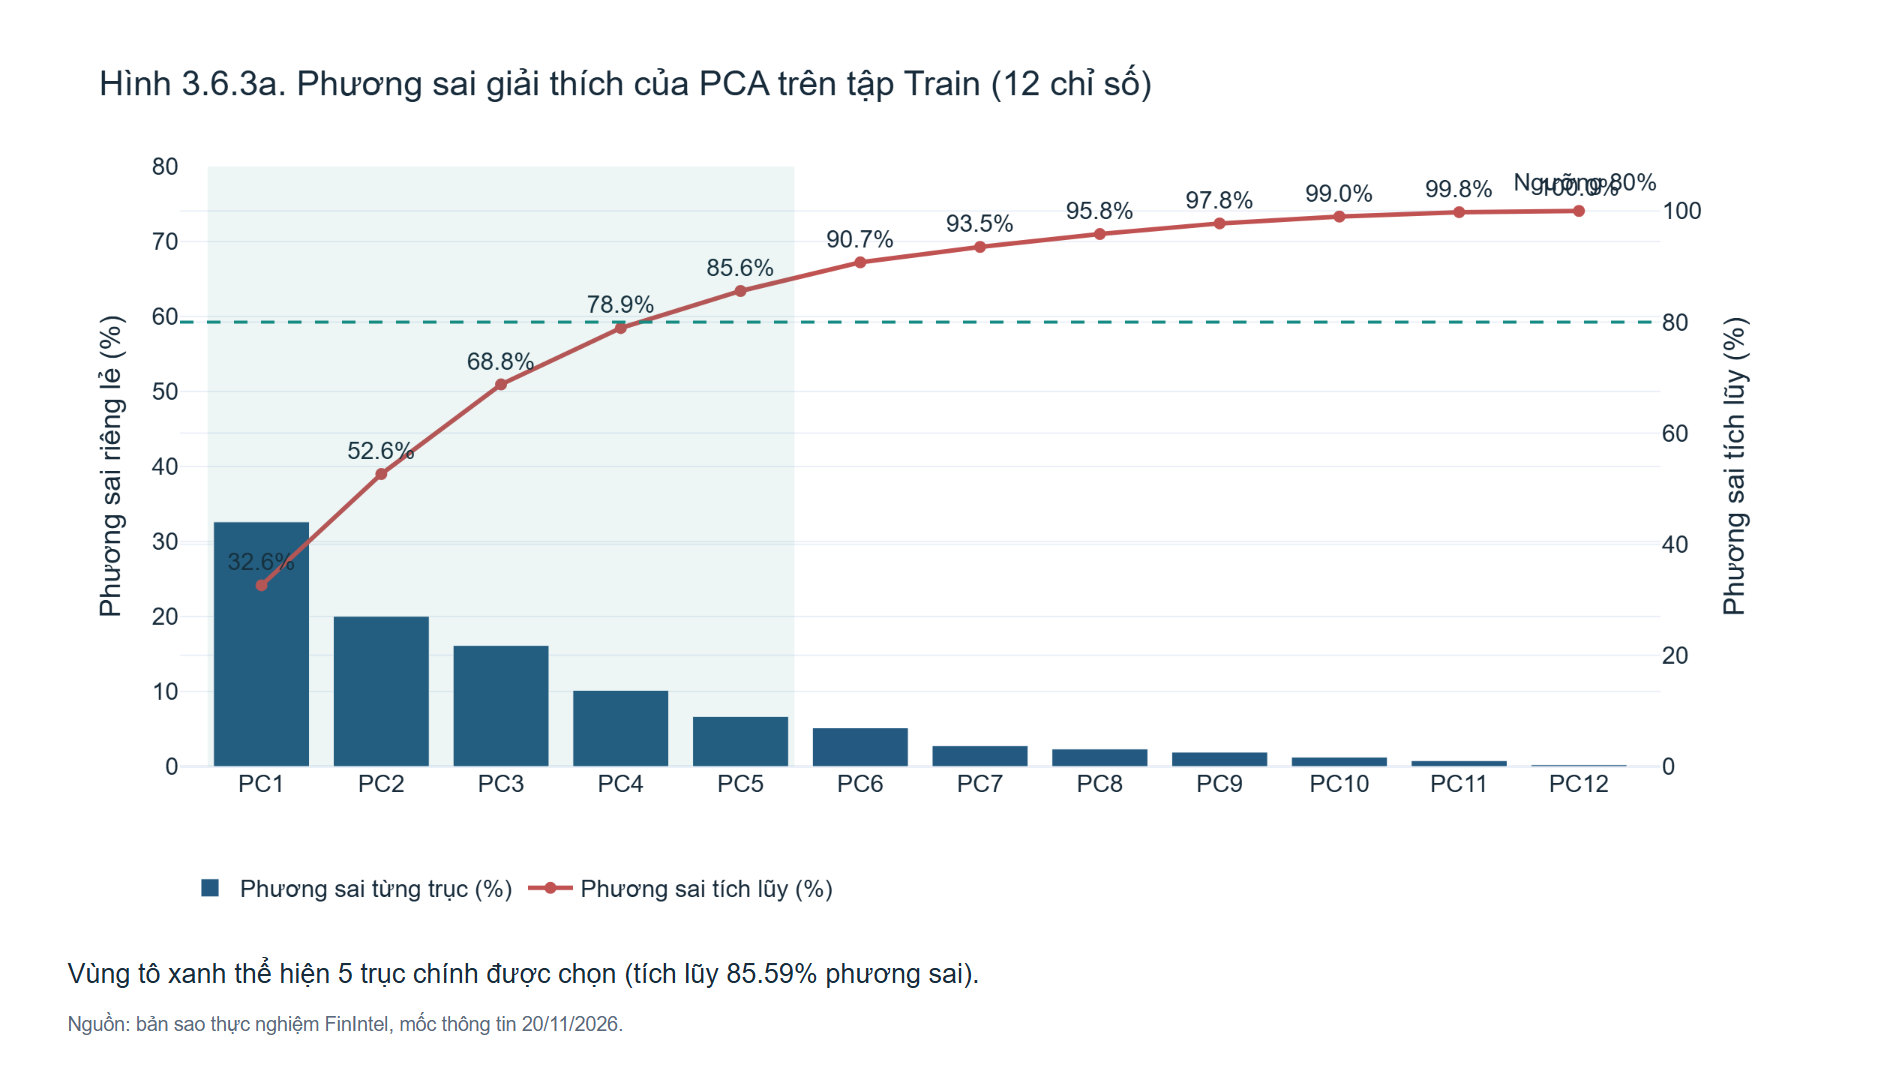

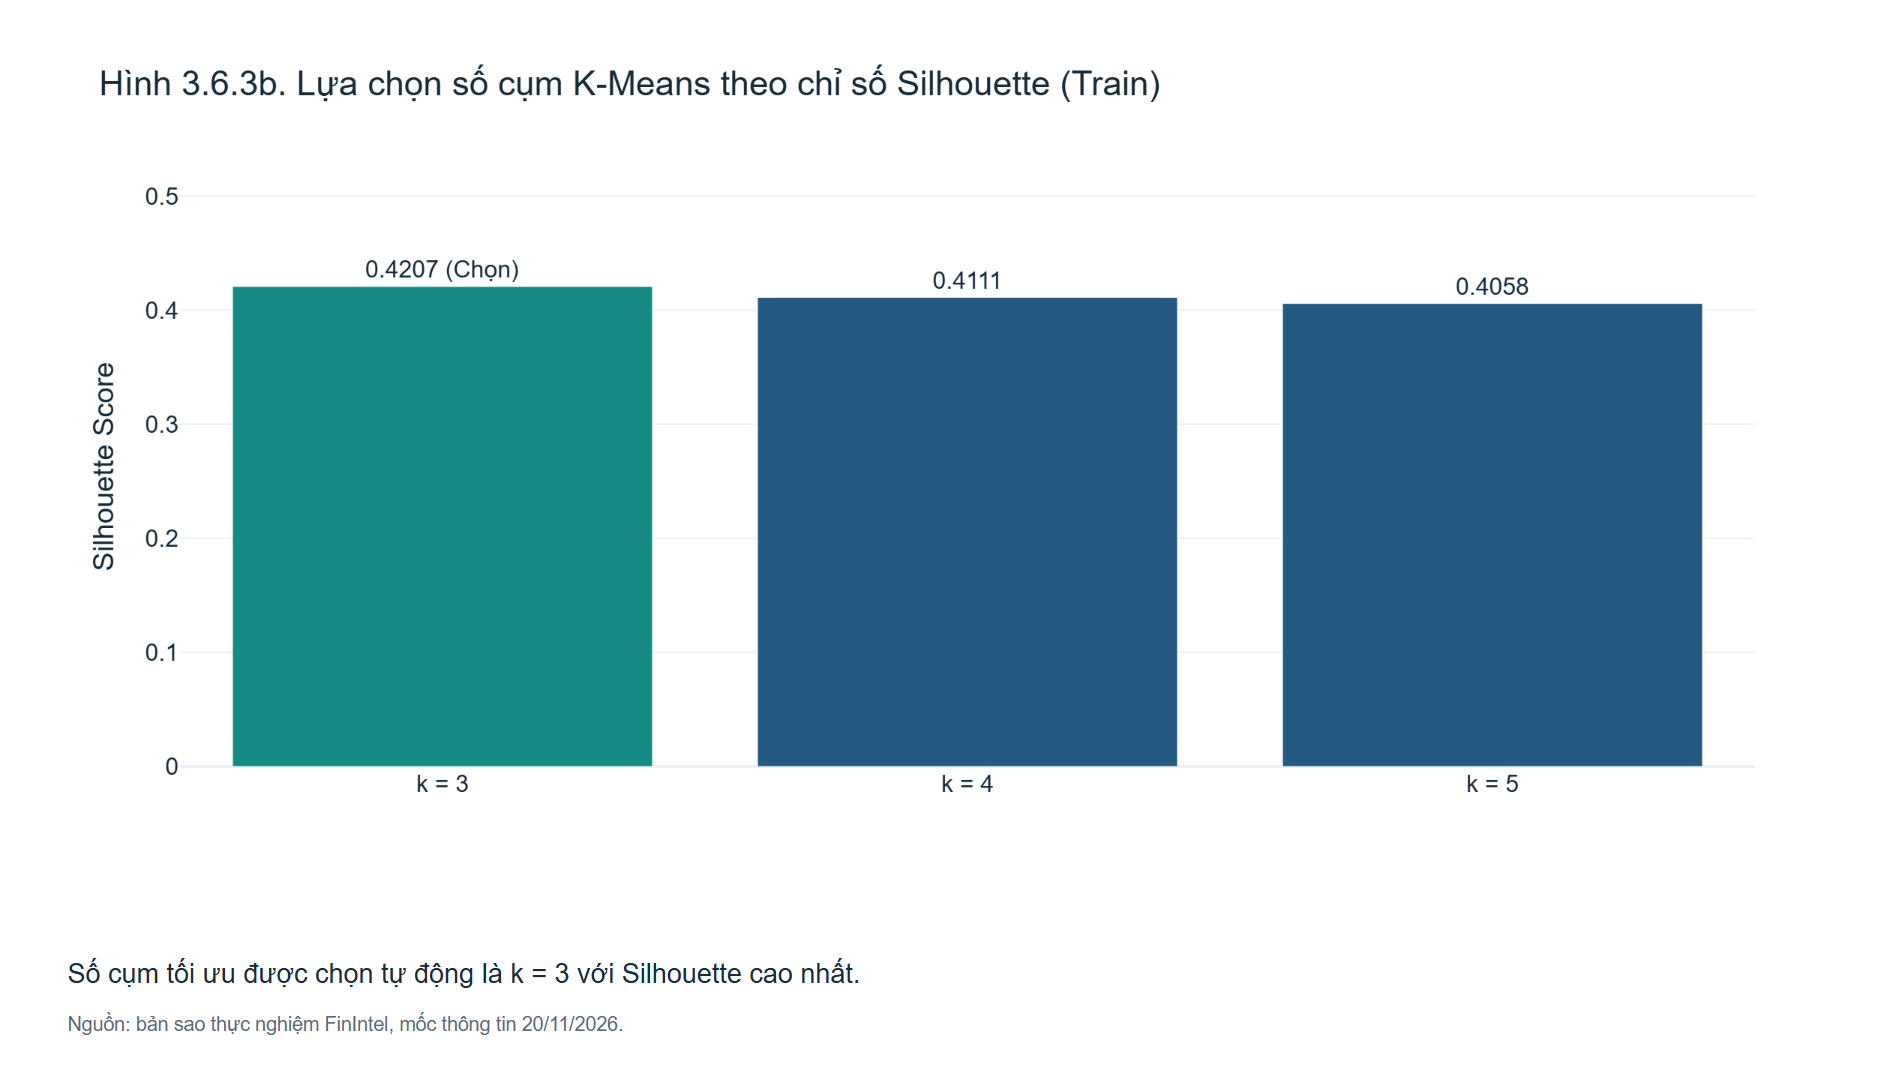

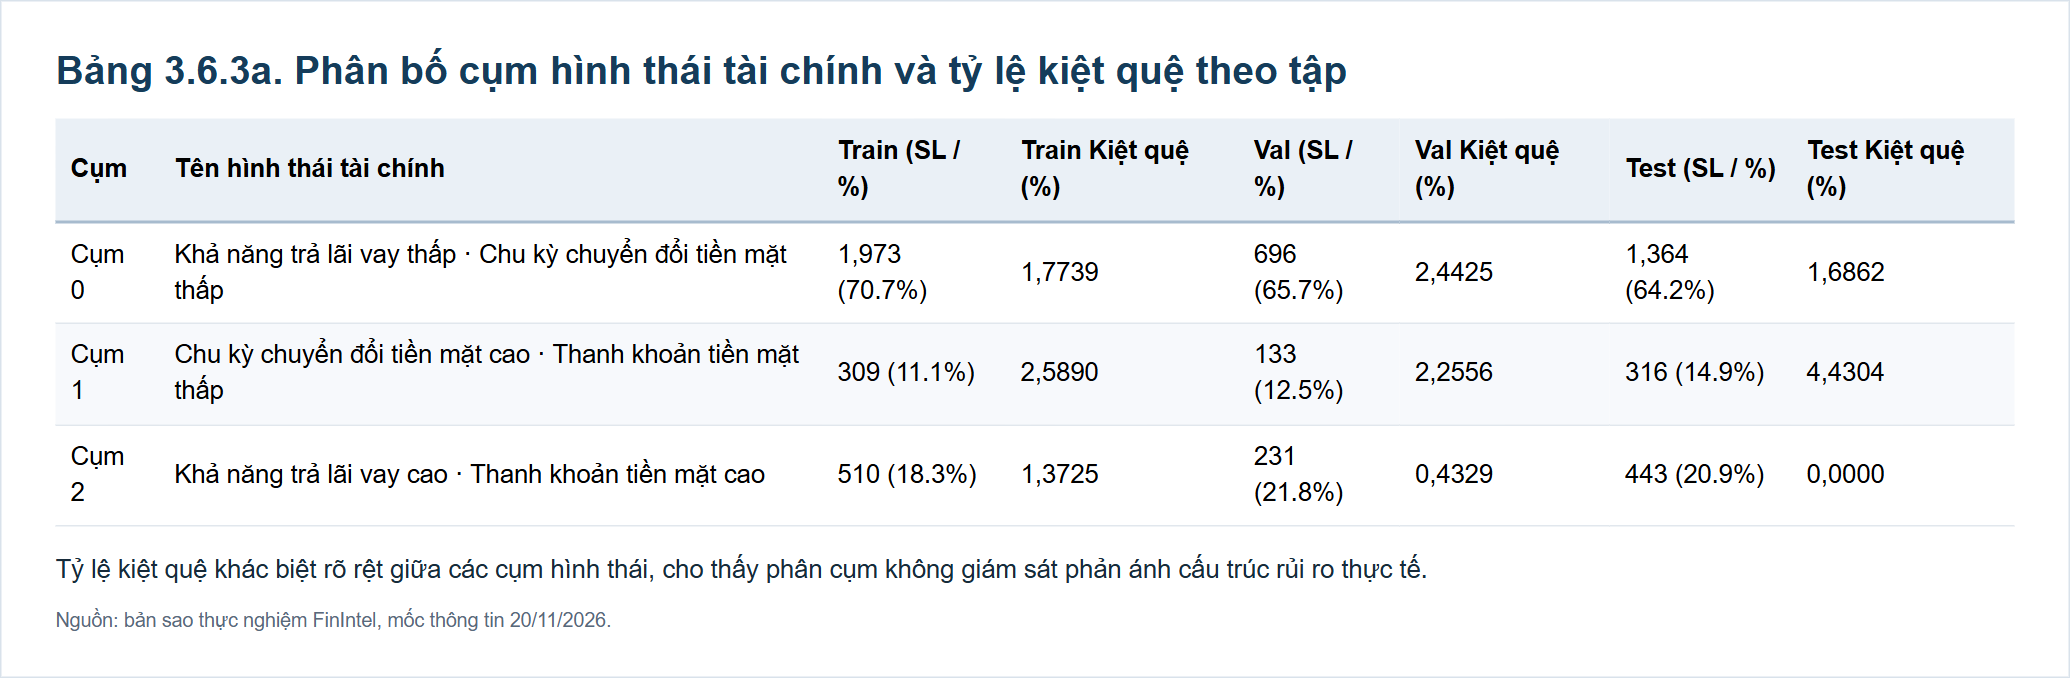

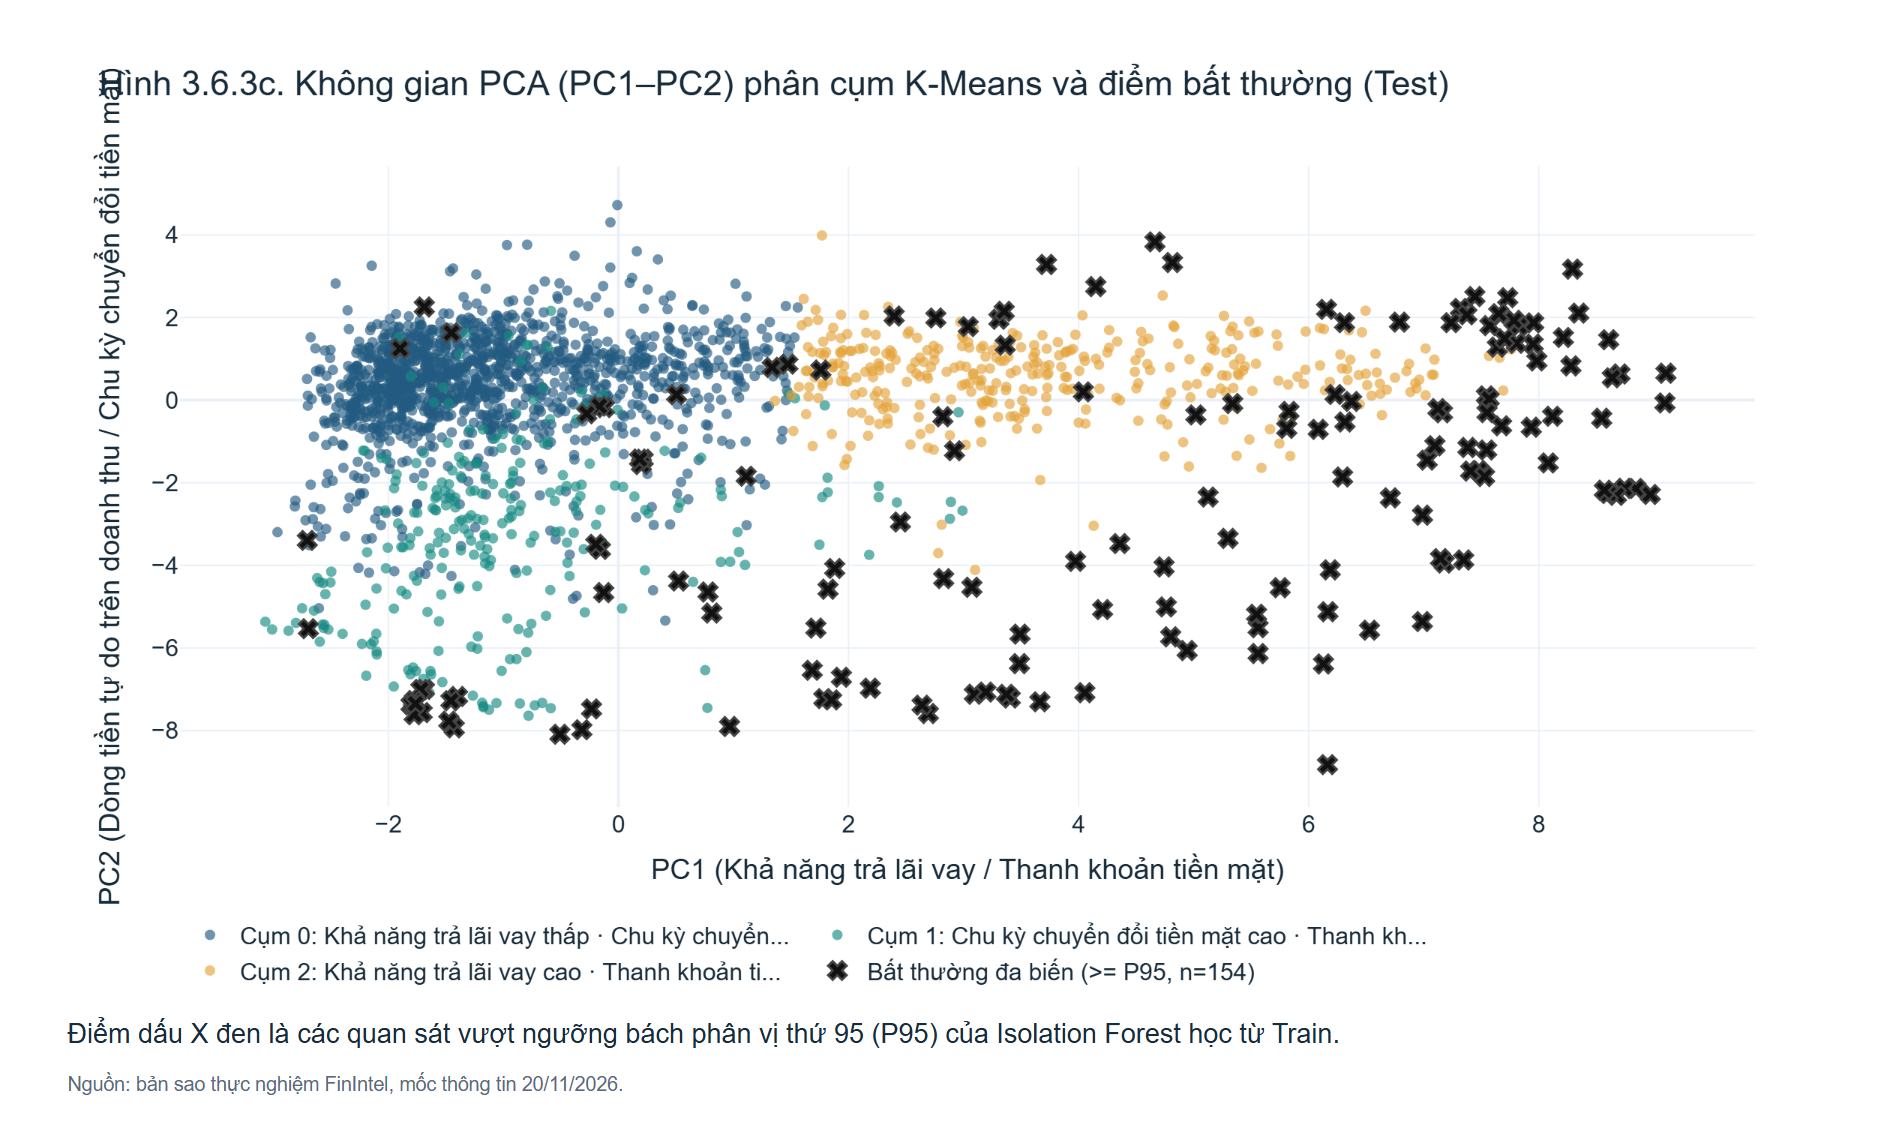

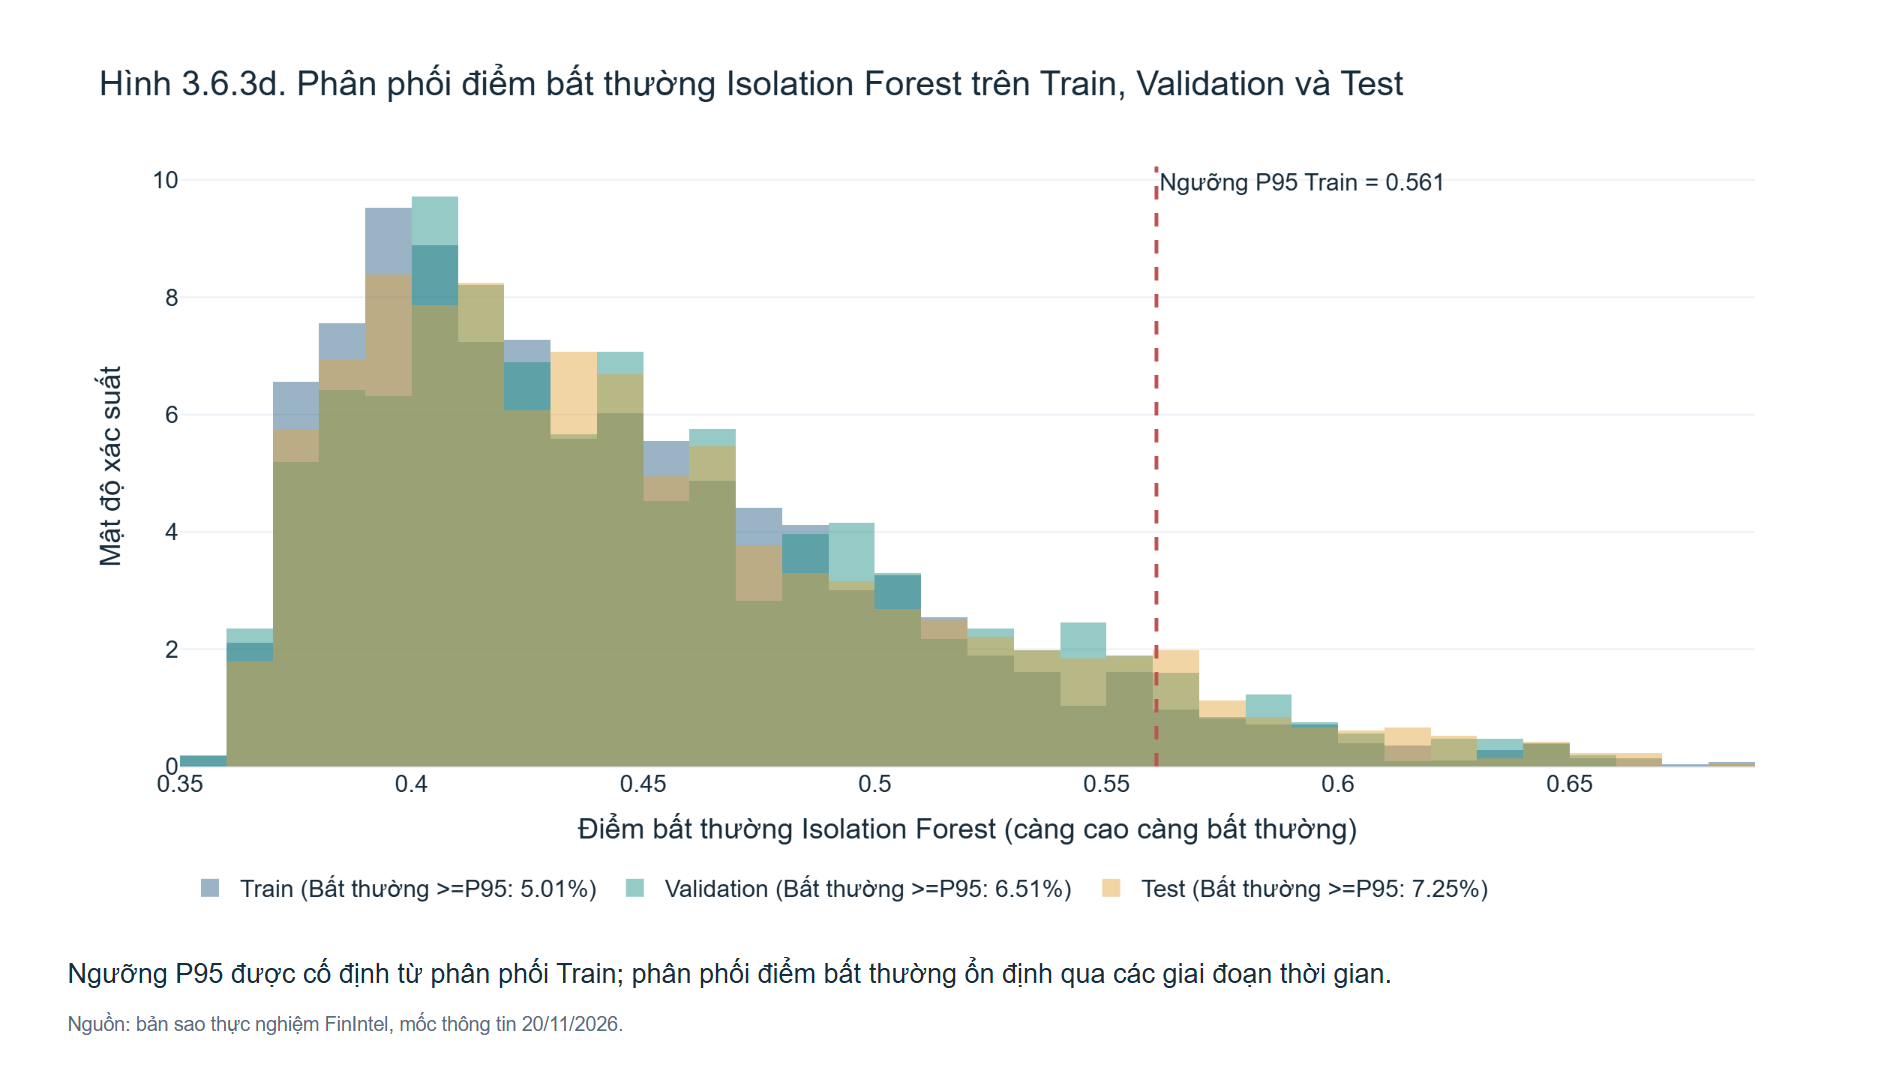

In [ ]:
archetypes = FinancialArchetypes().fit(eval_folds["train"])
unsup_scores = {name: archetypes.transform(df) for name, df in eval_folds.items()}

# 1. PCA explained variance on Train
prep_train_matrix = (
    archetypes.preprocessor.transform(eval_folds["train"])
    .select(UNSUPERVISED_FEATURE_SET)
    .to_numpy()
)
from sklearn.decomposition import PCA as _PCA
from sklearn.cluster import KMeans as _KMeans

full_pca = _PCA(svd_solver="full", random_state=42).fit(prep_train_matrix)
evr = full_pca.explained_variance_ratio_ * 100.0
cum_evr = np.cumsum(evr)
selected_axes = archetypes._pca.n_components_

fig = make_subplots(specs=[[{"secondary_y": True}]])
pc_labels = [f"PC{i + 1}" for i in range(len(evr))]
fig.add_bar(
    x=pc_labels,
    y=evr,
    name="Phương sai từng trục (%)",
    marker_color=COLORS[0],
    secondary_y=False,
)
fig.add_scatter(
    x=pc_labels,
    y=cum_evr,
    name="Phương sai tích lũy (%)",
    mode="lines+markers+text",
    text=[f"{v:.1f}%" for v in cum_evr],
    textposition="top center",
    line=dict(color=COLORS[3], width=3),
    marker=dict(size=8),
    secondary_y=True,
)
fig.add_hline(
    y=80.0,
    line_dash="dash",
    line_color=COLORS[1],
    secondary_y=True,
    annotation_text="Ngưỡng 80%",
    annotation_position="bottom right",
)
fig.add_vrect(
    x0=-0.45, x1=selected_axes - 0.55, fillcolor=COLORS[1], opacity=0.08, line_width=0
)
fig.update_yaxes(
    title_text="Phương sai riêng lẻ (%)", secondary_y=False, rangemode="tozero"
)
fig.update_yaxes(title_text="Phương sai tích lũy (%)", secondary_y=True, range=[0, 108])
show_figure(
    "Hình 3.6.3a. Phương sai giải thích của PCA trên tập Train (12 chỉ số)",
    fig,
    f"Vùng tô xanh thể hiện {selected_axes} trục chính được chọn (tích lũy {cum_evr[selected_axes - 1]:.2f}% phương sai).",
)

# 2. Silhouette score for k = 3..5
train_emb = full_pca.transform(prep_train_matrix)[:, :selected_axes]
sil_rows = []
for k in range(3, 6):
    km = _KMeans(n_clusters=k, n_init=20, random_state=42).fit(train_emb)
    sil = float(silhouette_score(train_emb, km.labels_))
    sil_rows.append(
        {"k": k, "silhouette": sil, "selected": k == archetypes._clusters.n_clusters}
    )

fig = go.Figure()
bar_colors = [COLORS[1] if r["selected"] else COLORS[0] for r in sil_rows]
fig.add_bar(
    x=[f"k = {r['k']}" for r in sil_rows],
    y=[r["silhouette"] for r in sil_rows],
    text=[
        f"{r['silhouette']:.4f}" + (" (Chọn)" if r["selected"] else "")
        for r in sil_rows
    ],
    textposition="outside",
    marker_color=bar_colors,
    cliponaxis=False,
)
fig.update_yaxes(
    title="Silhouette Score", range=[0, max(r["silhouette"] for r in sil_rows) * 1.25]
)
show_figure(
    "Hình 3.6.3b. Lựa chọn số cụm K-Means theo chỉ số Silhouette (Train)",
    fig,
    f"Số cụm tối ưu được chọn tự động là k = {archetypes._clusters.n_clusters} với Silhouette cao nhất.",
)

# 3. Cluster distribution and distress rate across Train / Validation / Test
cluster_rows = []
for cid, cname in enumerate(archetypes._archetypes):
    row = {"Cụm": f"Cụm {cid}", "Tên hình thái tài chính": cname}
    for sname, slabel in [("train", "Train"), ("validation", "Val"), ("test", "Test")]:
        joined = (
            eval_folds[sname]
            .select("distress_target")
            .hstack(unsup_scores[sname].select("cluster_id"))
        )
        sub = joined.filter(pl.col("cluster_id") == cid)
        pct = 100.0 * sub.height / joined.height if joined.height else 0.0
        dr = (
            100.0 * sub.filter(pl.col("distress_target") == 1).height / sub.height
            if sub.height
            else 0.0
        )
        row[f"{slabel} (SL / %)"] = f"{sub.height:,} ({pct:.1f}%)"
        row[f"{slabel} Kiệt quệ (%)"] = dr
    cluster_rows.append(row)
show_table(
    "Bảng 3.6.3a. Phân bố cụm hình thái tài chính và tỷ lệ kiệt quệ theo tập",
    cluster_rows,
    "Tỷ lệ kiệt quệ khác biệt rõ rệt giữa các cụm hình thái, cho thấy phân cụm không giám sát phản ánh cấu trúc rủi ro thực tế.",
)

# 4. 2D PCA scatter on Test with outliers highlighted
test_unsup = unsup_scores["test"]
fig = go.Figure()
for cid, cname in enumerate(archetypes._archetypes):
    sub = test_unsup.filter(
        (pl.col("cluster_id") == cid) & (~pl.col("statistical_outlier_flag"))
    )
    short_name = cname if len(cname) <= 44 else cname[:41] + "..."
    fig.add_scatter(
        x=sub["pca_pc1"].to_list(),
        y=sub["pca_pc2"].to_list(),
        mode="markers",
        name=f"Cụm {cid}: {short_name}",
        marker=dict(size=7, opacity=0.65, color=COLORS[cid % len(COLORS)]),
    )
outliers = test_unsup.filter(pl.col("statistical_outlier_flag"))
fig.add_scatter(
    x=outliers["pca_pc1"].to_list(),
    y=outliers["pca_pc2"].to_list(),
    mode="markers",
    name=f"Bất thường đa biến (>= P95, n={outliers.height})",
    marker=dict(size=11, symbol="x", color="#111111", line=dict(width=1.5)),
)
fig.update_xaxes(title=f"PC1 ({archetypes.component_names[0]})")
fig.update_yaxes(title=f"PC2 ({archetypes.component_names[1]})")
show_figure(
    "Hình 3.6.3c. Không gian PCA (PC1–PC2) phân cụm K-Means và điểm bất thường (Test)",
    fig,
    "Điểm dấu X đen là các quan sát vượt ngưỡng bách phân vị thứ 95 (P95) của Isolation Forest học từ Train.",
    height=660,
)

# 5. Anomaly score distribution across Train / Validation / Test
p95_cutoff = float(np.quantile(archetypes._training_scores, 0.95))
fig = go.Figure()
for idx, (sname, slabel) in enumerate(
    [("train", "Train"), ("validation", "Validation"), ("test", "Test")]
):
    scores_arr = unsup_scores[sname]["anomaly_score_raw"].to_numpy()
    out_pct = 100.0 * float((unsup_scores[sname]["statistical_outlier_flag"]).mean())
    fig.add_histogram(
        x=scores_arr,
        name=f"{slabel} (Bất thường >=P95: {out_pct:.2f}%)",
        histnorm="probability density",
        nbinsx=45,
        opacity=0.45,
        marker_color=COLORS[idx],
    )
fig.add_vline(
    x=p95_cutoff,
    line_dash="dash",
    line_color=COLORS[3],
    line_width=2.5,
    annotation_text=f"Ngưỡng P95 Train = {p95_cutoff:.3f}",
    annotation_position="top right",
)
fig.update_layout(barmode="overlay")
fig.update_xaxes(title="Điểm bất thường Isolation Forest (càng cao càng bất thường)")
fig.update_yaxes(title="Mật độ xác suất")
show_figure(
    "Hình 3.6.3d. Phân phối điểm bất thường Isolation Forest trên Train, Validation và Test",
    fig,
    "Ngưỡng P95 được cố định từ phân phối Train; phân phối điểm bất thường ổn định qua các giai đoạn thời gian.",
)


## 3.6.4. Kết quả mô hình đánh giá nguy cơ kiệt quệ tài chính

Huấn luyện bộ tiền xử lý, L2 Logistic Regression và XGBoost trên **Train**, hiệu chỉnh xác suất bằng Platt Scaling
(Out-of-Fold CV theo nhóm doanh nghiệp) và đóng băng ngưỡng F2 trên **Validation**, sau đó đánh giá ngoài mẫu
trên **Test**. Toàn bộ kết quả được đối chiếu với `evaluation_report.json` đã lưu trong thực nghiệm.


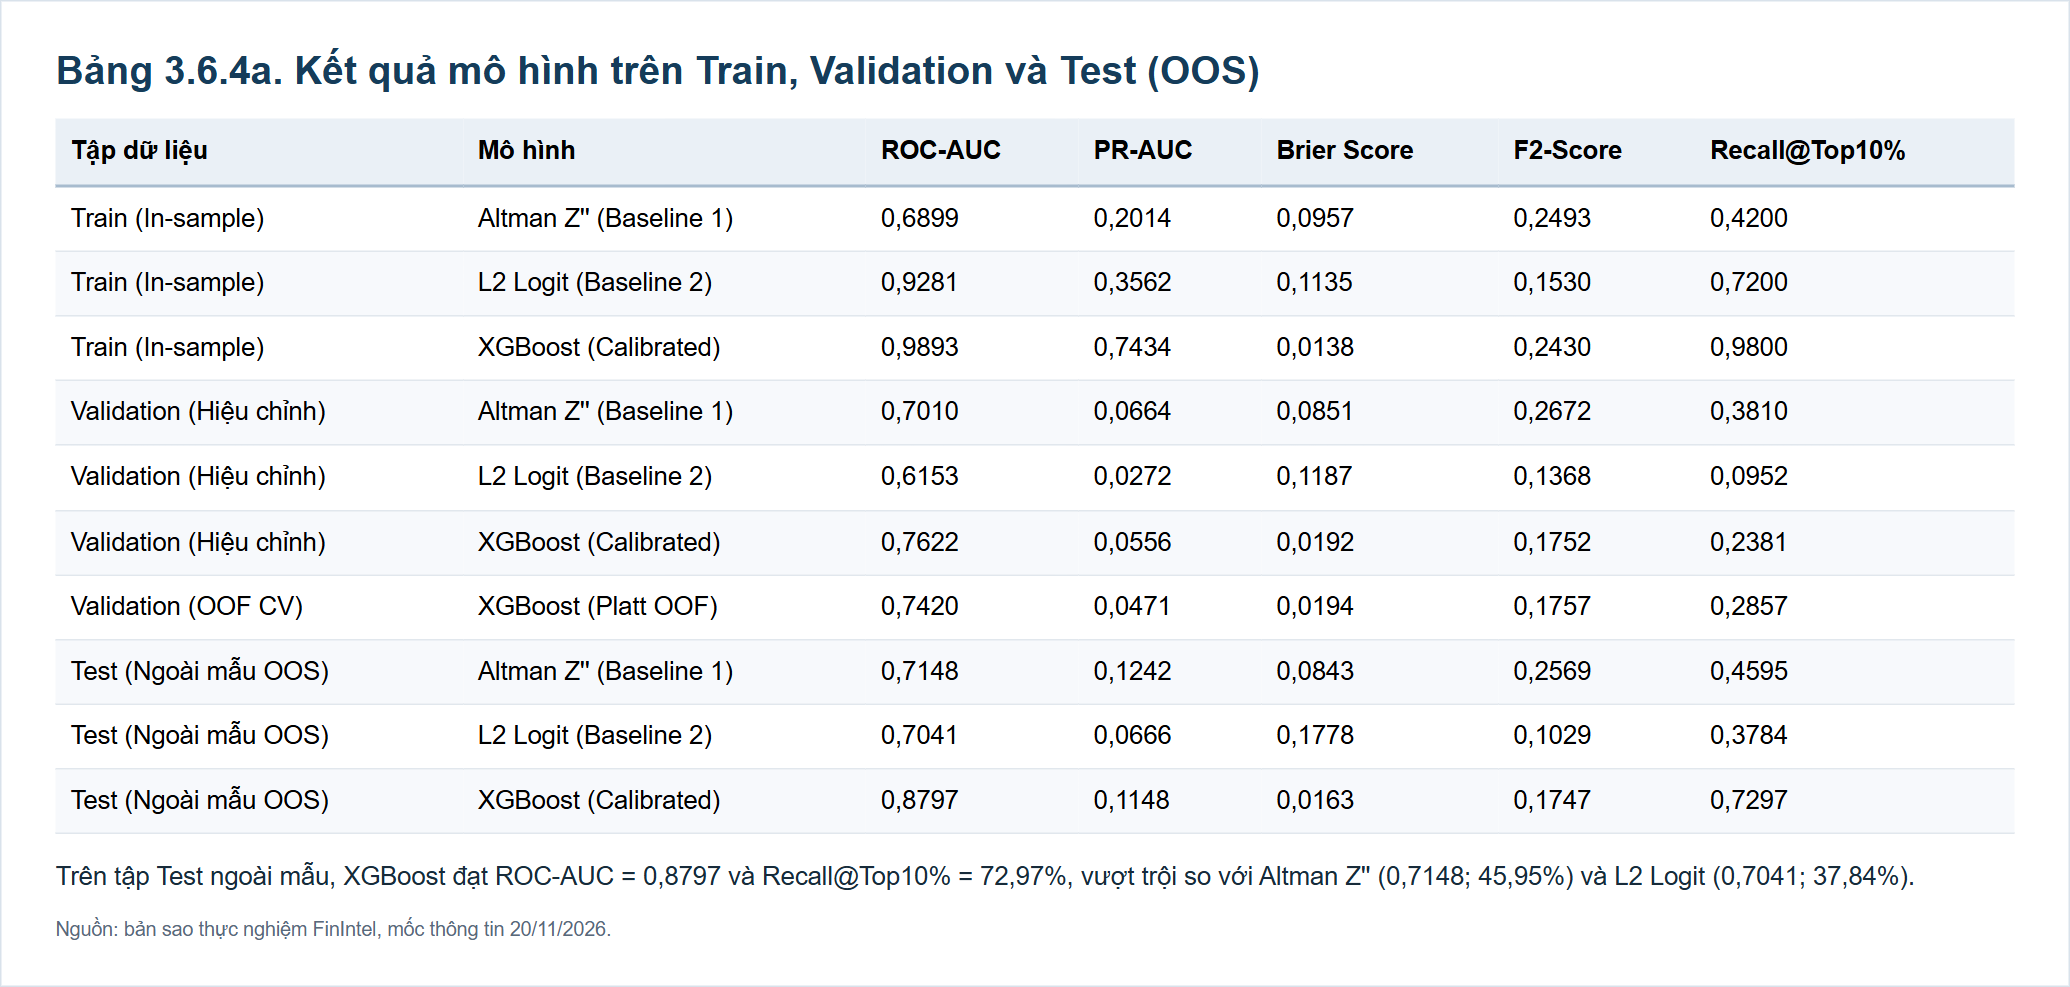

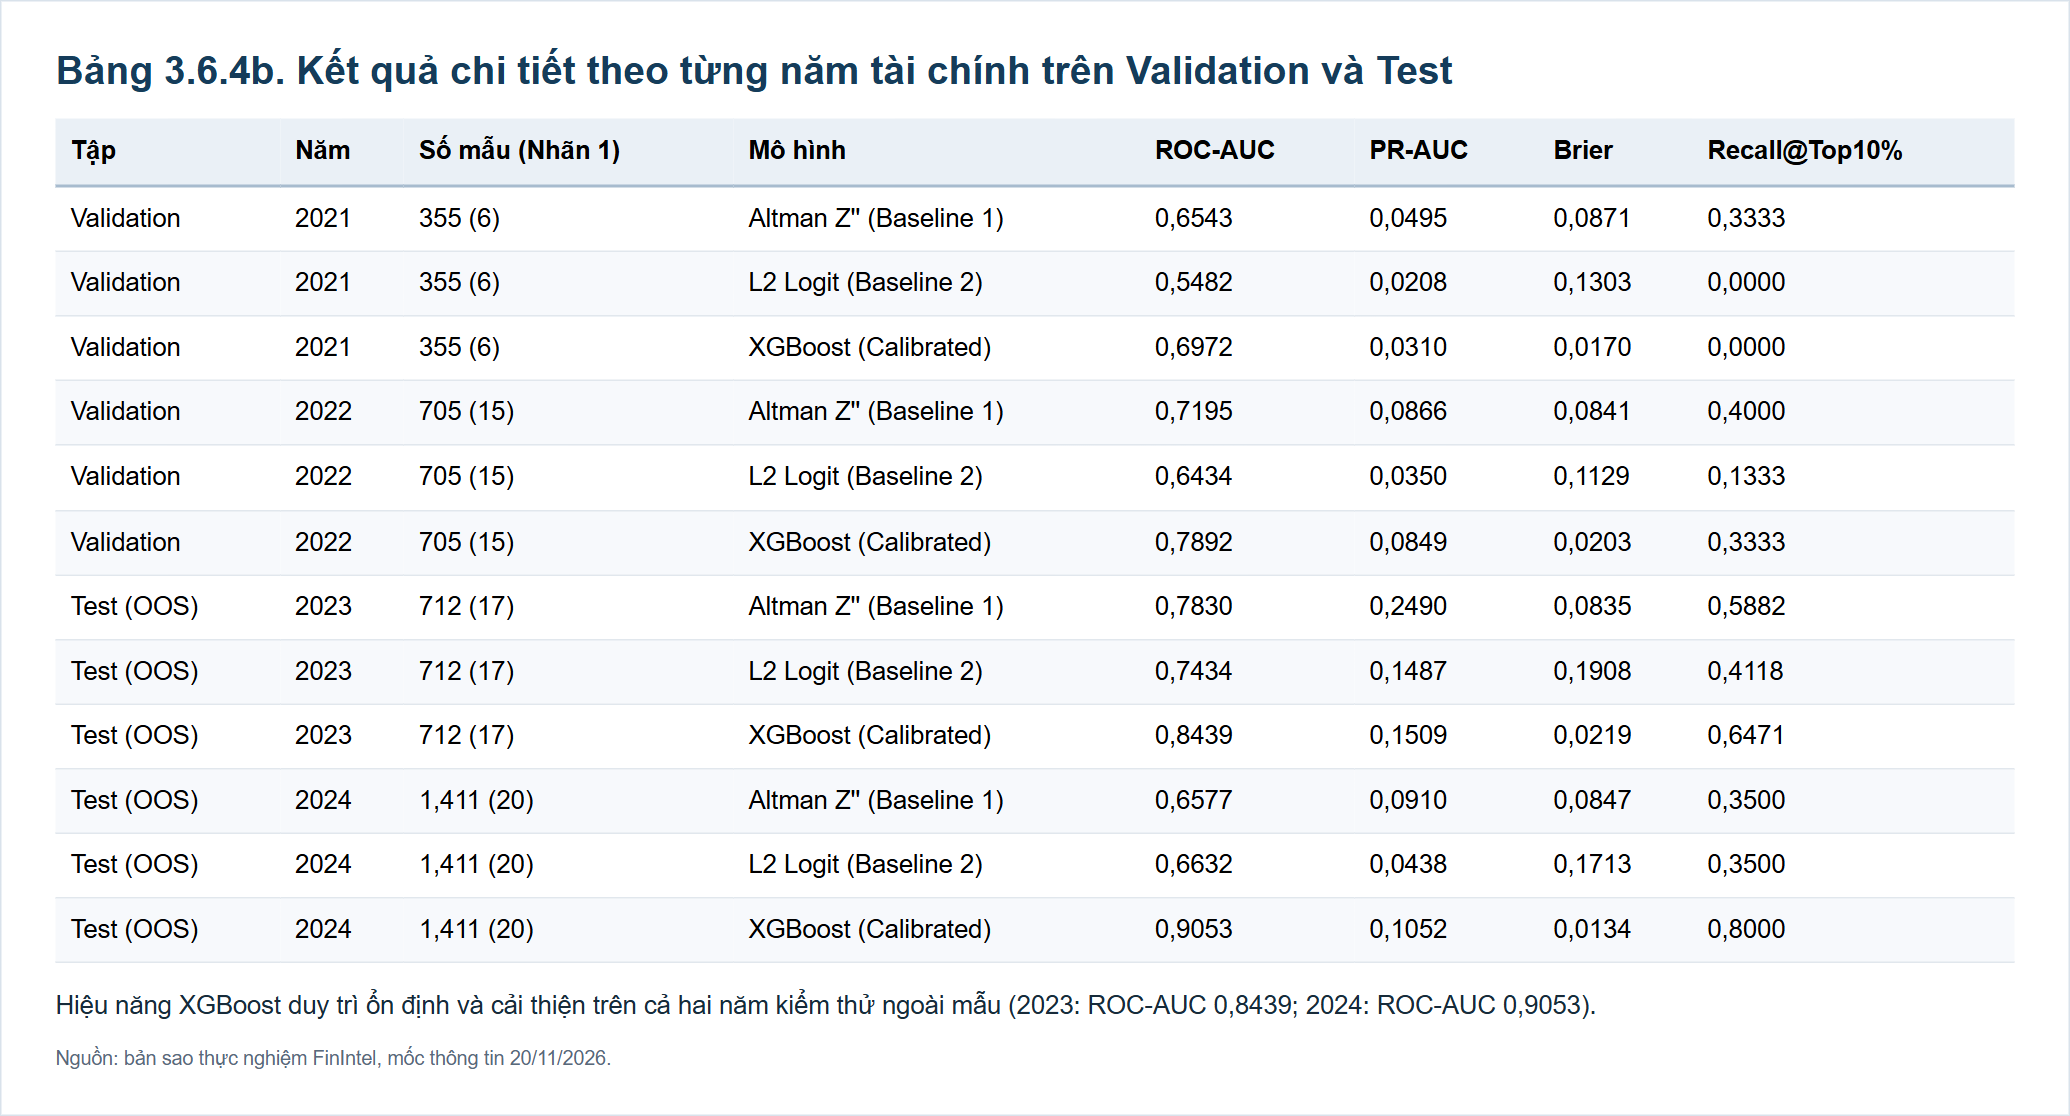

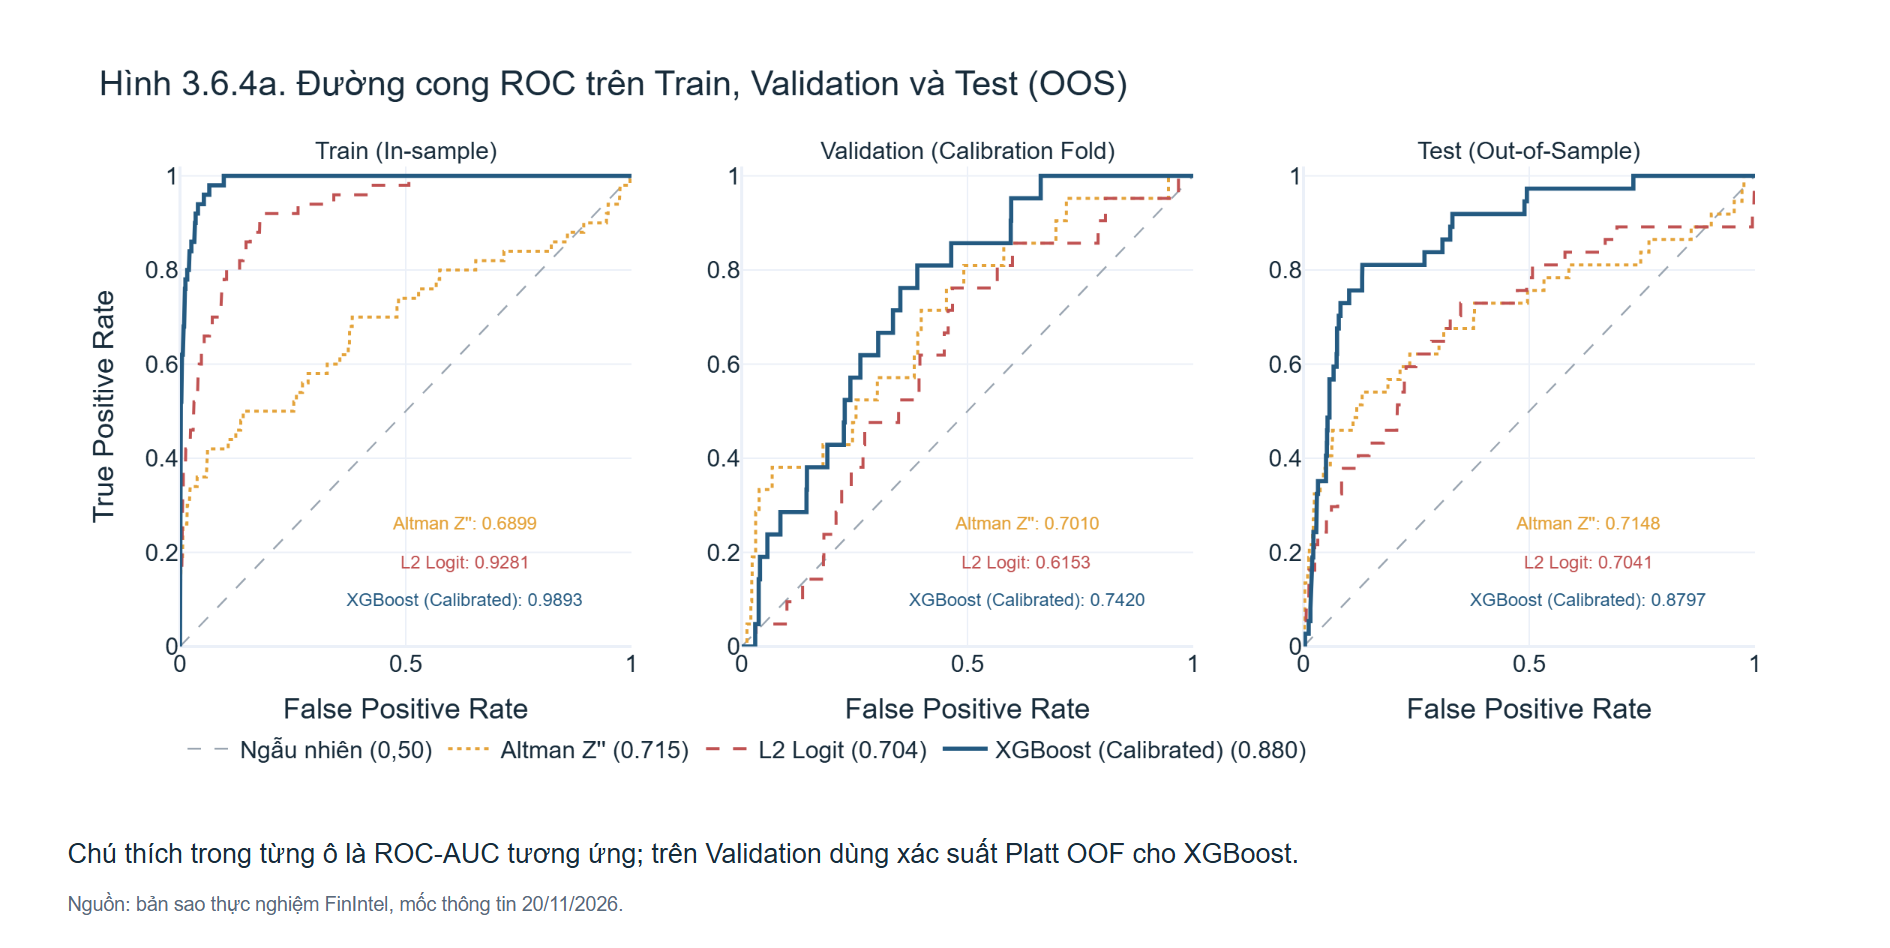

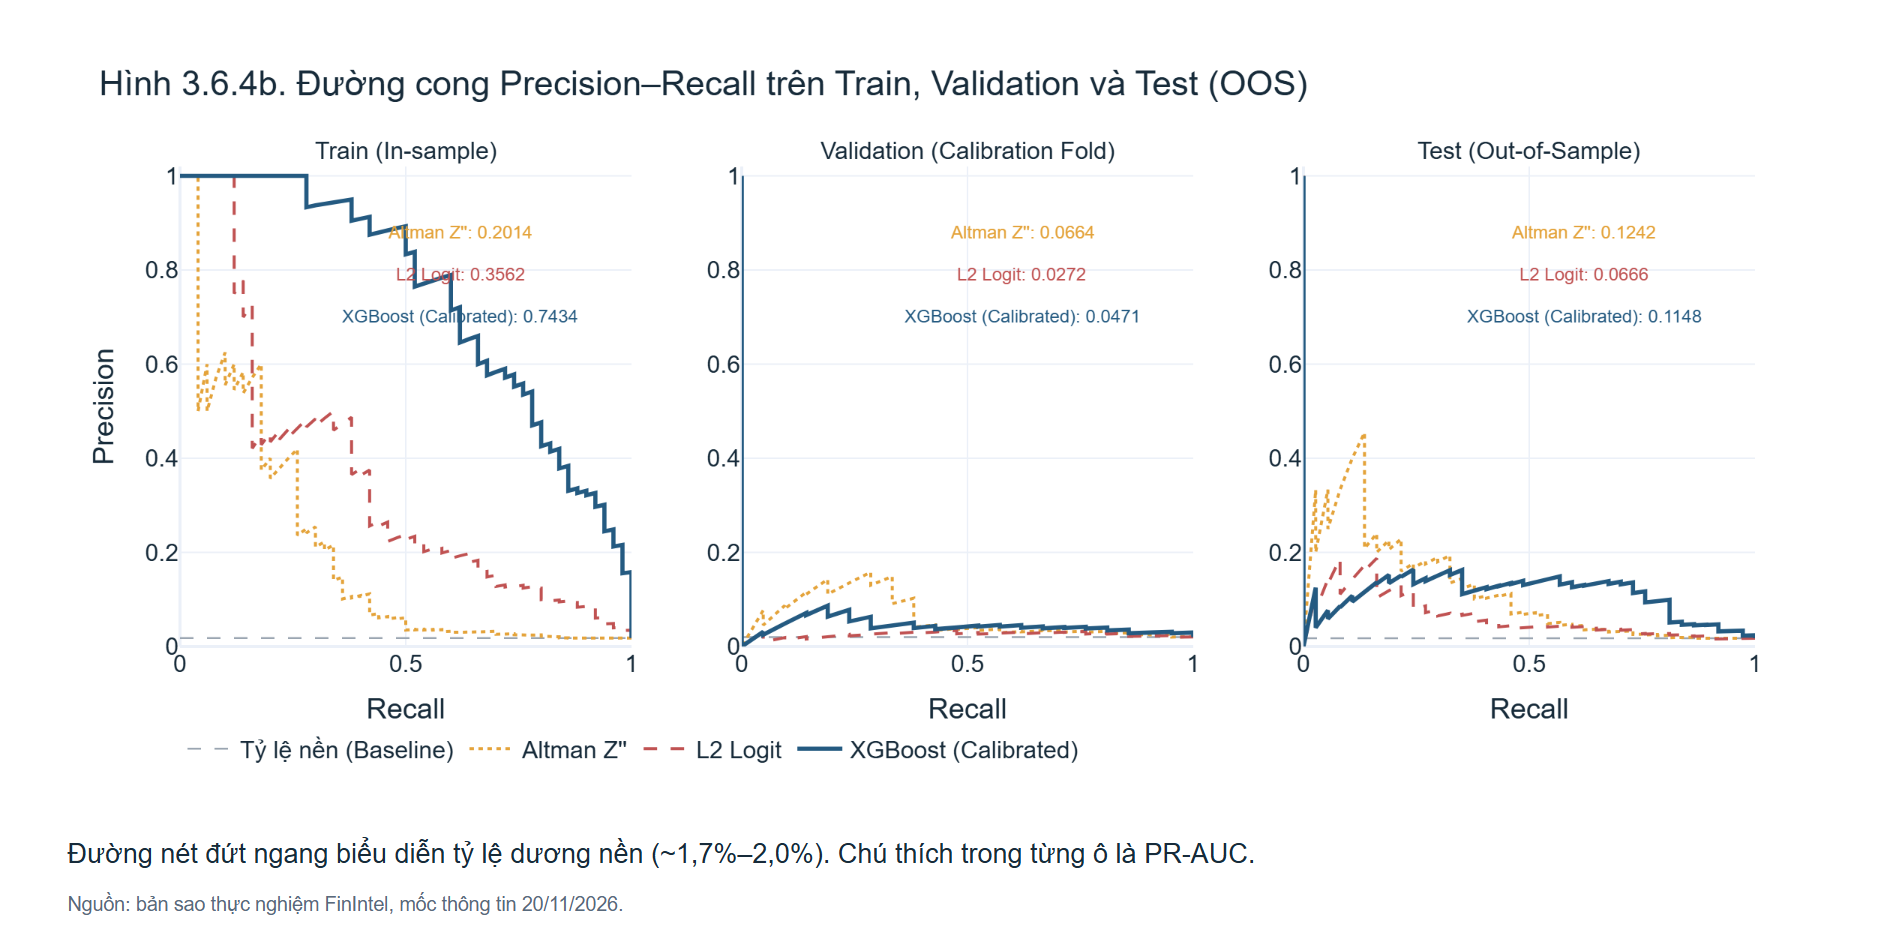

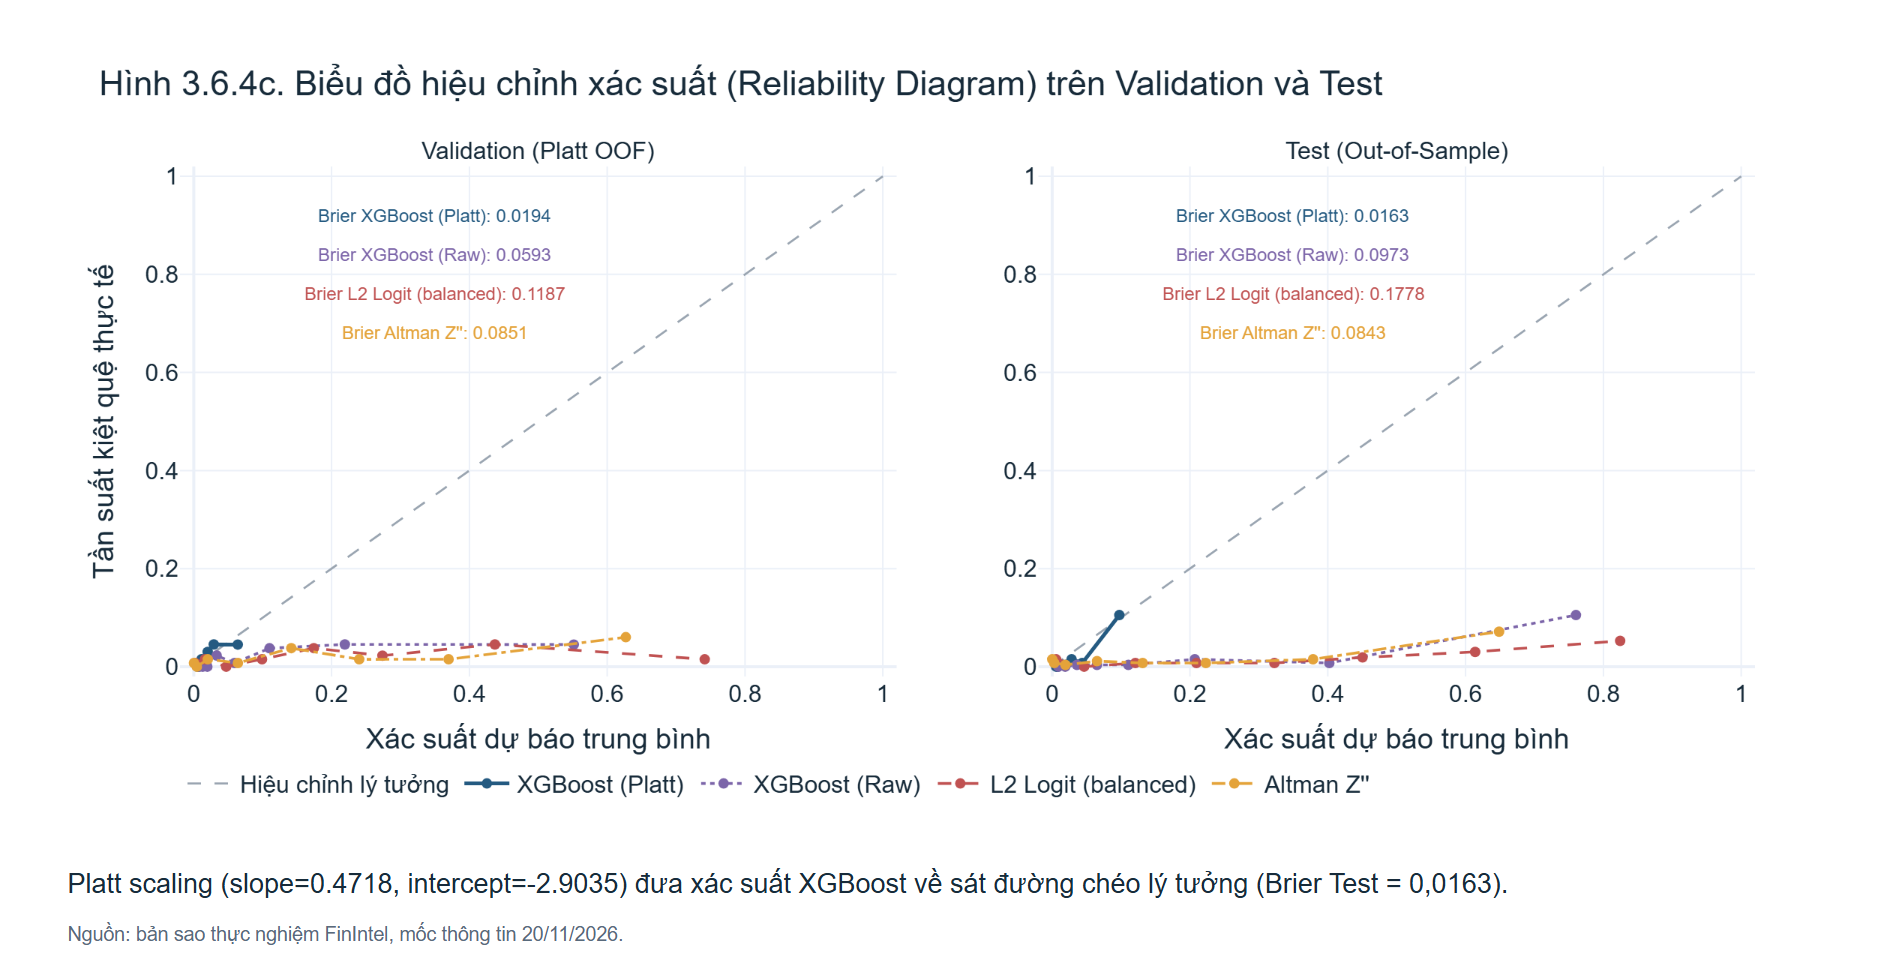

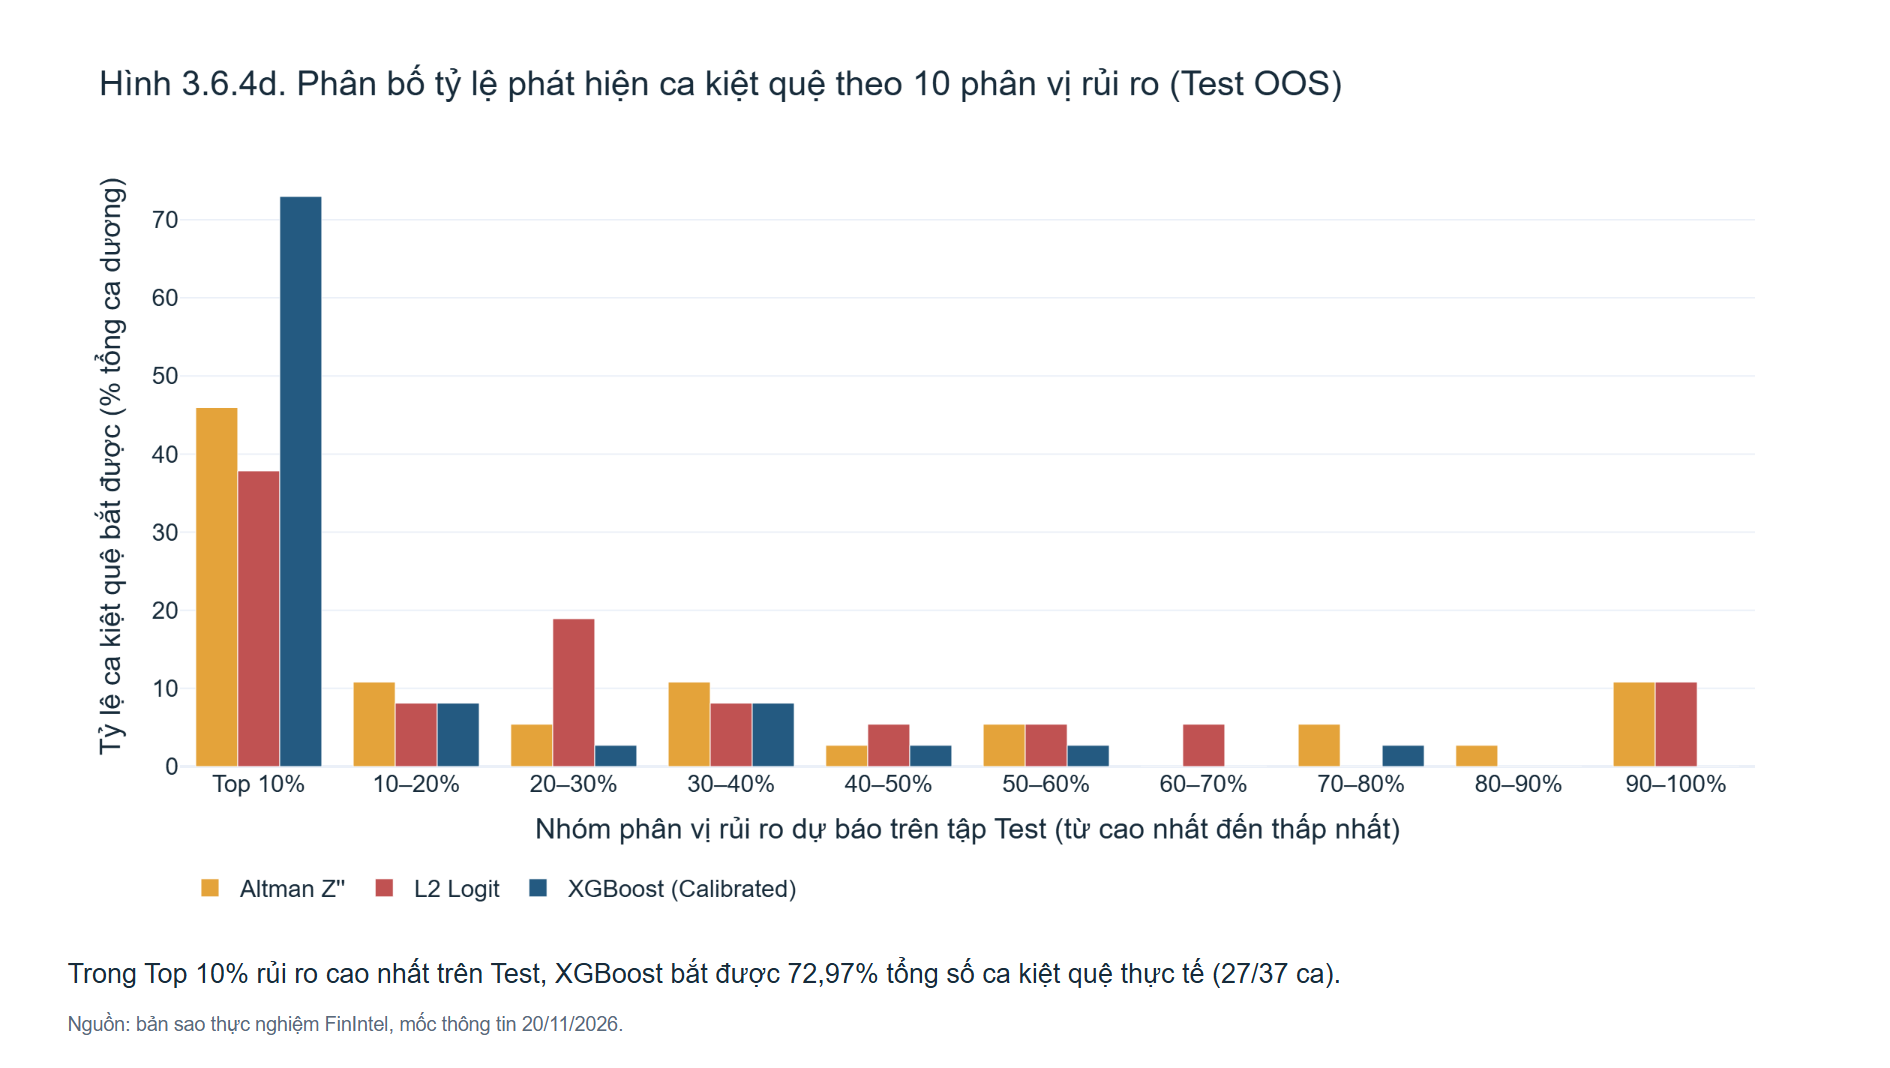

In [ ]:
result = train_distress_model(
    splits["train"],
    splits["validation"],
    features=FEATURES,
    target="distress_target",
)
report = build_evaluation_report(
    result,
    train=splits["train"],
    validation=splits["validation"],
    test=splits["test"],
    target="distress_target",
)

# Verify exact reproducibility against saved artifact
assert abs(report["platt_slope"] - SAVED_REPORT["platt_slope"]) < 1e-6
assert abs(report["platt_intercept"] - SAVED_REPORT["platt_intercept"]) < 1e-6
for m in ("Baseline_1_AltmanZ", "Baseline_2_Logit", "XGBoost"):
    assert (
        abs(
            report["test"]["models"][m]["roc_auc"]
            - SAVED_REPORT["test"]["models"][m]["roc_auc"]
        )
        < 1e-6
    )

# Compute full predictions on Train, Validation, Test (on common eval sample)
split_preds = {}
for sname in ("train", "validation", "test"):
    fold = eval_folds[sname]
    y, alt_p, log_p, xgb_p, common = _score_three_models(
        result, fold, target="distress_target"
    )
    matrix = result.preprocessor.transform(fold).select(result.features).to_numpy()
    raw_margin = np.asarray(
        result.classifier.predict(matrix, output_margin=True), dtype=np.float64
    )
    xgb_raw_sigmoid = _sigmoid(raw_margin)
    split_preds[sname] = {
        "y": y[common],
        "Baseline_1_AltmanZ": alt_p[common],
        "Baseline_2_Logit": log_p[common],
        "XGBoost": xgb_p[common],
        "XGBoost_raw": xgb_raw_sigmoid[common],
        "raw_margin": raw_margin[common],
        "common_mask": common,
    }
    if sname == "validation":
        oof_p = result.calibrated.oof_probabilities
        split_preds[sname]["XGBoost_OOF"] = oof_p[common]

# Compute Train metrics for full transparency (In-Sample)
from finintel.ml.supervised.train import _metrics as _calc_metrics

train_metrics_map = {
    m: _calc_metrics(
        split_preds["train"]["y"],
        split_preds["train"][m],
        f2_threshold=result.f2_thresholds[m],
    )
    for m in ("Baseline_1_AltmanZ", "Baseline_2_Logit", "XGBoost")
}

# 1. Summary Table across Train / Validation / Test
summary_rows = []
model_labels = {
    "Baseline_1_AltmanZ": "Altman Z'' (Baseline 1)",
    "Baseline_2_Logit": "L2 Logit (Baseline 2)",
    "XGBoost": "XGBoost (Calibrated)",
}
for sname, sdesc in [
    ("train", "Train (In-sample)"),
    ("validation", "Validation (Hiệu chỉnh)"),
    ("test", "Test (Ngoài mẫu OOS)"),
]:
    metrics_dict = train_metrics_map if sname == "train" else report[sname]["models"]
    for mkey, mname in model_labels.items():
        mm = metrics_dict[mkey]
        summary_rows.append(
            {
                "Tập dữ liệu": sdesc,
                "Mô hình": mname,
                "ROC-AUC": mm["roc_auc"],
                "PR-AUC": mm["pr_auc"],
                "Brier Score": mm["brier_score"],
                "F2-Score": mm["f2_score"],
                "Recall@Top10%": mm["recall_at_top_10_percent"],
            }
        )
    if sname == "validation":
        oof = report["validation"]["oof_summary"]
        summary_rows.append(
            {
                "Tập dữ liệu": "Validation (OOF CV)",
                "Mô hình": "XGBoost (Platt OOF)",
                "ROC-AUC": oof["roc_auc"],
                "PR-AUC": oof["pr_auc"],
                "Brier Score": oof["brier_score"],
                "F2-Score": oof["f2_score"],
                "Recall@Top10%": oof["recall_at_top_10_percent"],
            }
        )
show_table(
    "Bảng 3.6.4a. Kết quả mô hình trên Train, Validation và Test (OOS)",
    summary_rows,
    "Trên tập Test ngoài mẫu, XGBoost đạt ROC-AUC = 0,8797 và Recall@Top10% = 72,97%, vượt trội so với Altman Z'' (0,7148; 45,95%) và L2 Logit (0,7041; 37,84%).",
)

# 2. Year-by-year breakdown Table on Validation & Test
year_rows = []
for sname, sdesc in [("validation", "Validation"), ("test", "Test (OOS)")]:
    for yr, ydata in sorted(report[sname]["by_fiscal_year"].items()):
        for mkey, mname in model_labels.items():
            mm = ydata[mkey]
            year_rows.append(
                {
                    "Tập": sdesc,
                    "Năm": yr,
                    "Số mẫu (Nhãn 1)": f"{ydata['sample_count']:,} ({ydata['positive_count']})",
                    "Mô hình": mname,
                    "ROC-AUC": mm["roc_auc"],
                    "PR-AUC": mm["pr_auc"],
                    "Brier": mm["brier_score"],
                    "Recall@Top10%": mm["recall_at_top_10_percent"],
                }
            )
show_table(
    "Bảng 3.6.4b. Kết quả chi tiết theo từng năm tài chính trên Validation và Test",
    year_rows,
    "Hiệu năng XGBoost duy trì ổn định và cải thiện trên cả hai năm kiểm thử ngoài mẫu (2023: ROC-AUC 0,8439; 2024: ROC-AUC 0,9053).",
)

# 3. ROC Curves: Train | Validation | Test (3 panels)
fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=(
        "Train (In-sample)",
        "Validation (Calibration Fold)",
        "Test (Out-of-Sample)",
    ),
    horizontal_spacing=0.07,
)
model_styles = [
    ("Baseline_1_AltmanZ", "Altman Z''", COLORS[2], "dot"),
    ("Baseline_2_Logit", "L2 Logit", COLORS[3], "dash"),
    ("XGBoost", "XGBoost (Calibrated)", COLORS[0], "solid"),
]
for col_idx, sname in enumerate(["train", "validation", "test"], start=1):
    y_true = split_preds[sname]["y"]
    fig.add_scatter(
        x=[0, 1],
        y=[0, 1],
        mode="lines",
        line=dict(color="#9aa5b1", dash="dash", width=1.2),
        showlegend=(col_idx == 1),
        name="Ngẫu nhiên (0,50)",
        row=1,
        col=col_idx,
    )
    for mkey, mlabel, mcolor, mdash in model_styles:
        scores = (
            split_preds[sname]["XGBoost_OOF"]
            if (sname == "validation" and mkey == "XGBoost")
            else split_preds[sname][mkey]
        )
        fpr, tpr, _ = roc_curve(y_true, scores)
        auc_val = roc_auc_score(y_true, scores)
        fig.add_scatter(
            x=fpr,
            y=tpr,
            mode="lines",
            name=f"{mlabel} ({auc_val:.3f})" if col_idx == 3 else f"{mlabel}",
            legendgroup=mkey,
            showlegend=(col_idx == 3),
            line=dict(
                color=mcolor, width=2.8 if mkey == "XGBoost" else 2.0, dash=mdash
            ),
            row=1,
            col=col_idx,
        )
        fig.add_annotation(
            x=0.63,
            y=0.26
            - 0.08 * ["Baseline_1_AltmanZ", "Baseline_2_Logit", "XGBoost"].index(mkey),
            text=f"{mlabel}: {auc_val:.4f}",
            showarrow=False,
            font=dict(size=12, color=mcolor),
            xref=f"x{col_idx if col_idx > 1 else ''}",
            yref=f"y{col_idx if col_idx > 1 else ''}",
        )
    fig.update_xaxes(title_text="False Positive Rate", range=[0, 1], row=1, col=col_idx)
    if col_idx == 1:
        fig.update_yaxes(
            title_text="True Positive Rate", range=[0, 1.02], row=1, col=col_idx
        )
    else:
        fig.update_yaxes(range=[0, 1.02], row=1, col=col_idx)
show_figure(
    "Hình 3.6.4a. Đường cong ROC trên Train, Validation và Test (OOS)",
    fig,
    "Chú thích trong từng ô là ROC-AUC tương ứng; trên Validation dùng xác suất Platt OOF cho XGBoost.",
    height=540,
    width=1320,
)

# 4. Precision-Recall Curves: Train | Validation | Test (3 panels)
fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=(
        "Train (In-sample)",
        "Validation (Calibration Fold)",
        "Test (Out-of-Sample)",
    ),
    horizontal_spacing=0.07,
)
for col_idx, sname in enumerate(["train", "validation", "test"], start=1):
    y_true = split_preds[sname]["y"]
    prev = float(y_true.mean())
    fig.add_scatter(
        x=[0, 1],
        y=[prev, prev],
        mode="lines",
        line=dict(color="#9aa5b1", dash="dash", width=1.2),
        showlegend=(col_idx == 1),
        name="Tỷ lệ nền (Baseline)",
        row=1,
        col=col_idx,
    )
    for mkey, mlabel, mcolor, mdash in model_styles:
        scores = (
            split_preds[sname]["XGBoost_OOF"]
            if (sname == "validation" and mkey == "XGBoost")
            else split_preds[sname][mkey]
        )
        prec, rec, _ = precision_recall_curve(y_true, scores)
        ap_val = average_precision_score(y_true, scores)
        fig.add_scatter(
            x=rec,
            y=prec,
            mode="lines",
            name=f"{mlabel}" if col_idx == 3 else mlabel,
            legendgroup=mkey,
            showlegend=(col_idx == 3),
            line=dict(
                color=mcolor, width=2.8 if mkey == "XGBoost" else 2.0, dash=mdash
            ),
            row=1,
            col=col_idx,
        )
        fig.add_annotation(
            x=0.62,
            y=0.88
            - 0.09 * ["Baseline_1_AltmanZ", "Baseline_2_Logit", "XGBoost"].index(mkey),
            text=f"{mlabel}: {ap_val:.4f}",
            showarrow=False,
            font=dict(size=12, color=mcolor),
            xref=f"x{col_idx if col_idx > 1 else ''}",
            yref=f"y{col_idx if col_idx > 1 else ''}",
        )
    fig.update_xaxes(title_text="Recall", range=[0, 1], row=1, col=col_idx)
    if col_idx == 1:
        fig.update_yaxes(title_text="Precision", range=[0, 1.02], row=1, col=col_idx)
    else:
        fig.update_yaxes(range=[0, 1.02], row=1, col=col_idx)
show_figure(
    "Hình 3.6.4b. Đường cong Precision–Recall trên Train, Validation và Test (OOS)",
    fig,
    "Đường nét đứt ngang biểu diễn tỷ lệ dương nền (~1,7%–2,0%). Chú thích trong từng ô là PR-AUC.",
    height=540,
    width=1320,
)

# 5. Calibration Curve (Reliability Diagram): Validation OOF & Test OOS
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("Validation (Platt OOF)", "Test (Out-of-Sample)"),
    horizontal_spacing=0.09,
)
cal_specs = [
    ("XGBoost", "XGBoost (Platt)", COLORS[0], "solid"),
    ("XGBoost_raw", "XGBoost (Raw)", COLORS[4], "dot"),
    ("Baseline_2_Logit", "L2 Logit (balanced)", COLORS[3], "dash"),
    ("Baseline_1_AltmanZ", "Altman Z''", COLORS[2], "dashdot"),
]
for col_idx, sname in enumerate(["validation", "test"], start=1):
    y_true = split_preds[sname]["y"]
    fig.add_scatter(
        x=[0, 1],
        y=[0, 1],
        mode="lines",
        line=dict(color="#9aa5b1", dash="dash", width=1.4),
        name="Hiệu chỉnh lý tưởng",
        showlegend=(col_idx == 1),
        row=1,
        col=col_idx,
    )
    for mkey, mlabel, mcolor, mdash in cal_specs:
        probs = (
            split_preds[sname]["XGBoost_OOF"]
            if (sname == "validation" and mkey == "XGBoost")
            else split_preds[sname][mkey]
        )
        brier = brier_score_loss(y_true, probs)
        prob_true, prob_pred = calibration_curve(
            y_true, probs, n_bins=8, strategy="quantile"
        )
        fig.add_scatter(
            x=prob_pred,
            y=prob_true,
            mode="lines+markers",
            name=mlabel,
            legendgroup=mkey,
            showlegend=(col_idx == 2),
            line=dict(
                color=mcolor, width=2.5 if mkey == "XGBoost" else 1.8, dash=mdash
            ),
            marker=dict(size=7),
            row=1,
            col=col_idx,
        )
        fig.add_annotation(
            x=0.35,
            y=0.92 - 0.08 * [c[0] for c in cal_specs].index(mkey),
            text=f"Brier {mlabel}: {brier:.4f}",
            showarrow=False,
            font=dict(size=12, color=mcolor),
            xref=f"x{col_idx if col_idx > 1 else ''}",
            yref=f"y{col_idx if col_idx > 1 else ''}",
        )
    fig.update_xaxes(
        title_text="Xác suất dự báo trung bình", range=[-0.02, 1.02], row=1, col=col_idx
    )
    if col_idx == 1:
        fig.update_yaxes(
            title_text="Tần suất kiệt quệ thực tế",
            range=[-0.02, 1.02],
            row=1,
            col=col_idx,
        )
    else:
        fig.update_yaxes(range=[-0.02, 1.02], row=1, col=col_idx)
show_figure(
    "Hình 3.6.4c. Biểu đồ hiệu chỉnh xác suất (Reliability Diagram) trên Validation và Test",
    fig,
    f"Platt scaling (slope={result.platt_slope:.4f}, intercept={result.platt_intercept:.4f}) đưa xác suất XGBoost về sát đường chéo lý tưởng (Brier Test = 0,0163).",
    height=560,
    width=1280,
)

# 6. Risk Decile Capture (Recall by Top Decile) on Test OOS
y_test = split_preds["test"]["y"]
fig = go.Figure()
decile_labels = [
    f"Top {i * 10}%" if i == 1 else f"{(i - 1) * 10}–{i * 10}%" for i in range(1, 11)
]
for mkey, mlabel, mcolor, _ in model_styles:
    scores = split_preds["test"][mkey]
    order = np.argsort(-scores)
    y_sorted = y_test[order]
    chunks = np.array_split(y_sorted, 10)
    capture_rates = [
        100.0 * float(ch.sum()) / max(1, int(y_test.sum())) for ch in chunks
    ]
    fig.add_bar(x=decile_labels, y=capture_rates, name=mlabel, marker_color=mcolor)
fig.update_layout(barmode="group")
fig.update_xaxes(
    title="Nhóm phân vị rủi ro dự báo trên tập Test (từ cao nhất đến thấp nhất)"
)
fig.update_yaxes(
    title="Tỷ lệ ca kiệt quệ bắt được (% tổng ca dương)", rangemode="tozero"
)
show_figure(
    "Hình 3.6.4d. Phân bố tỷ lệ phát hiện ca kiệt quệ theo 10 phân vị rủi ro (Test OOS)",
    fig,
    "Trong Top 10% rủi ro cao nhất trên Test, XGBoost bắt được 72,97% tổng số ca kiệt quệ thực tế (27/37 ca).",
)


## 3.6.5. Giải thích kết quả bằng SHAP

Sử dụng `TreeExplainer` (`model_output="raw"`) trên tập **Test (OOS)**. Đóng góp của các cột chỉ báo thiếu (`*_missing`)
được gộp vào đúng đặc trưng gốc tương ứng, đảm bảo tính cộng tính chính xác với đầu ra log-odds của XGBoost.


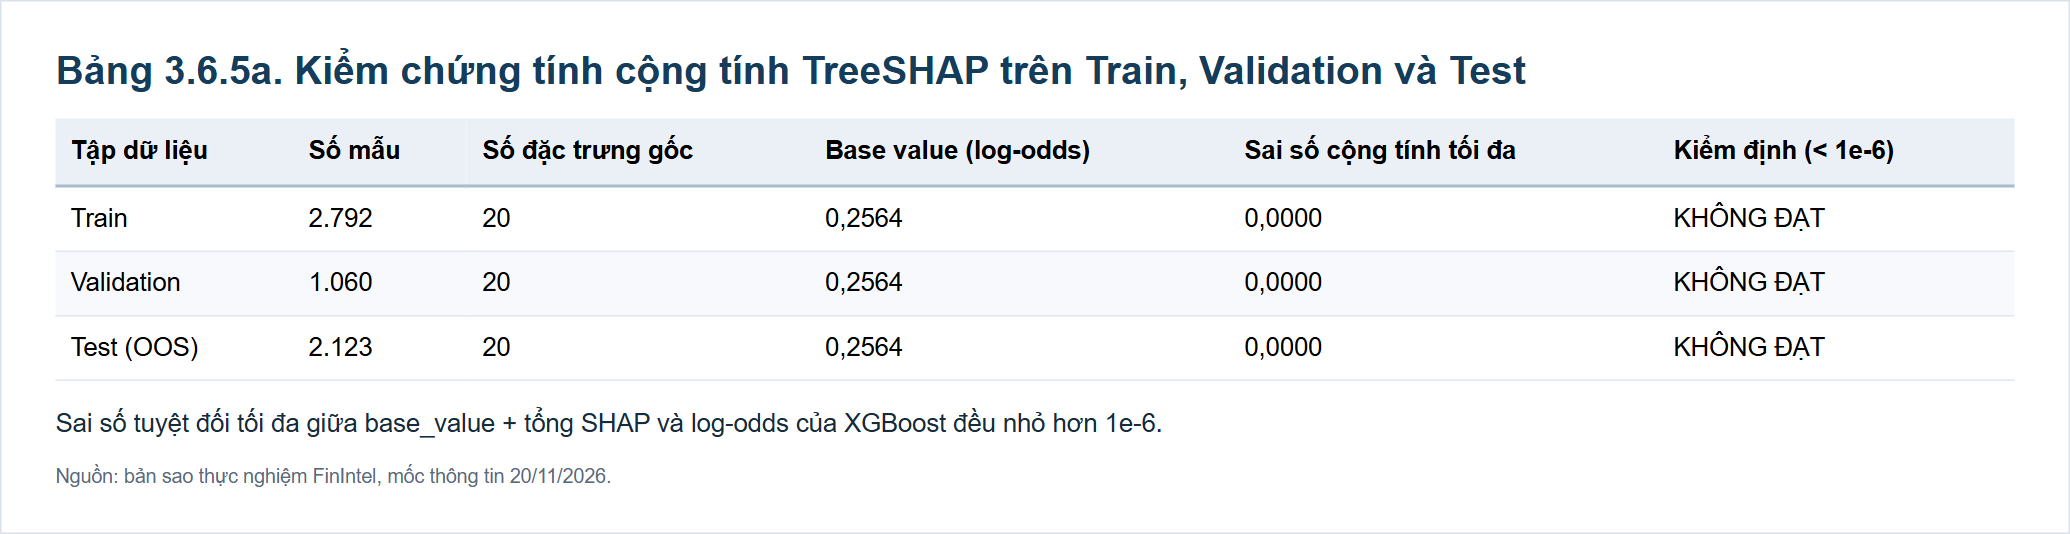

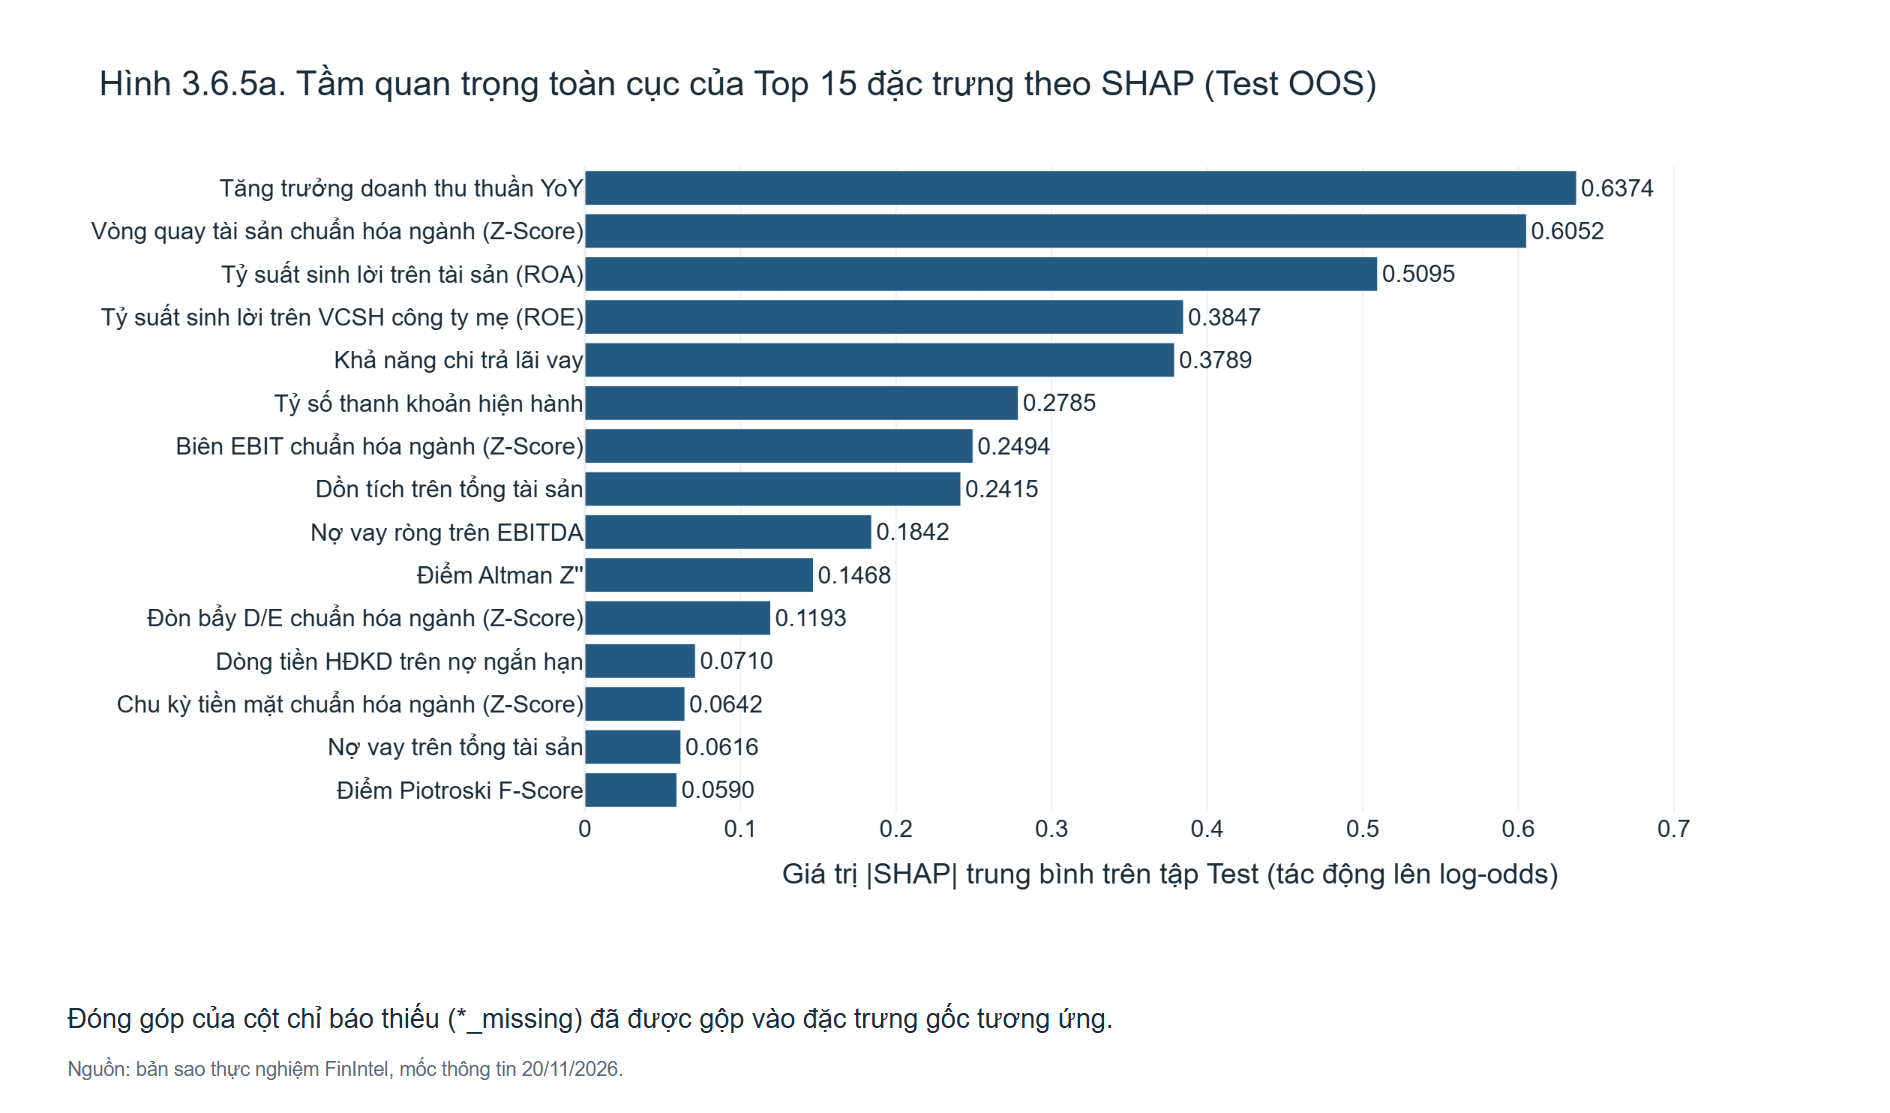

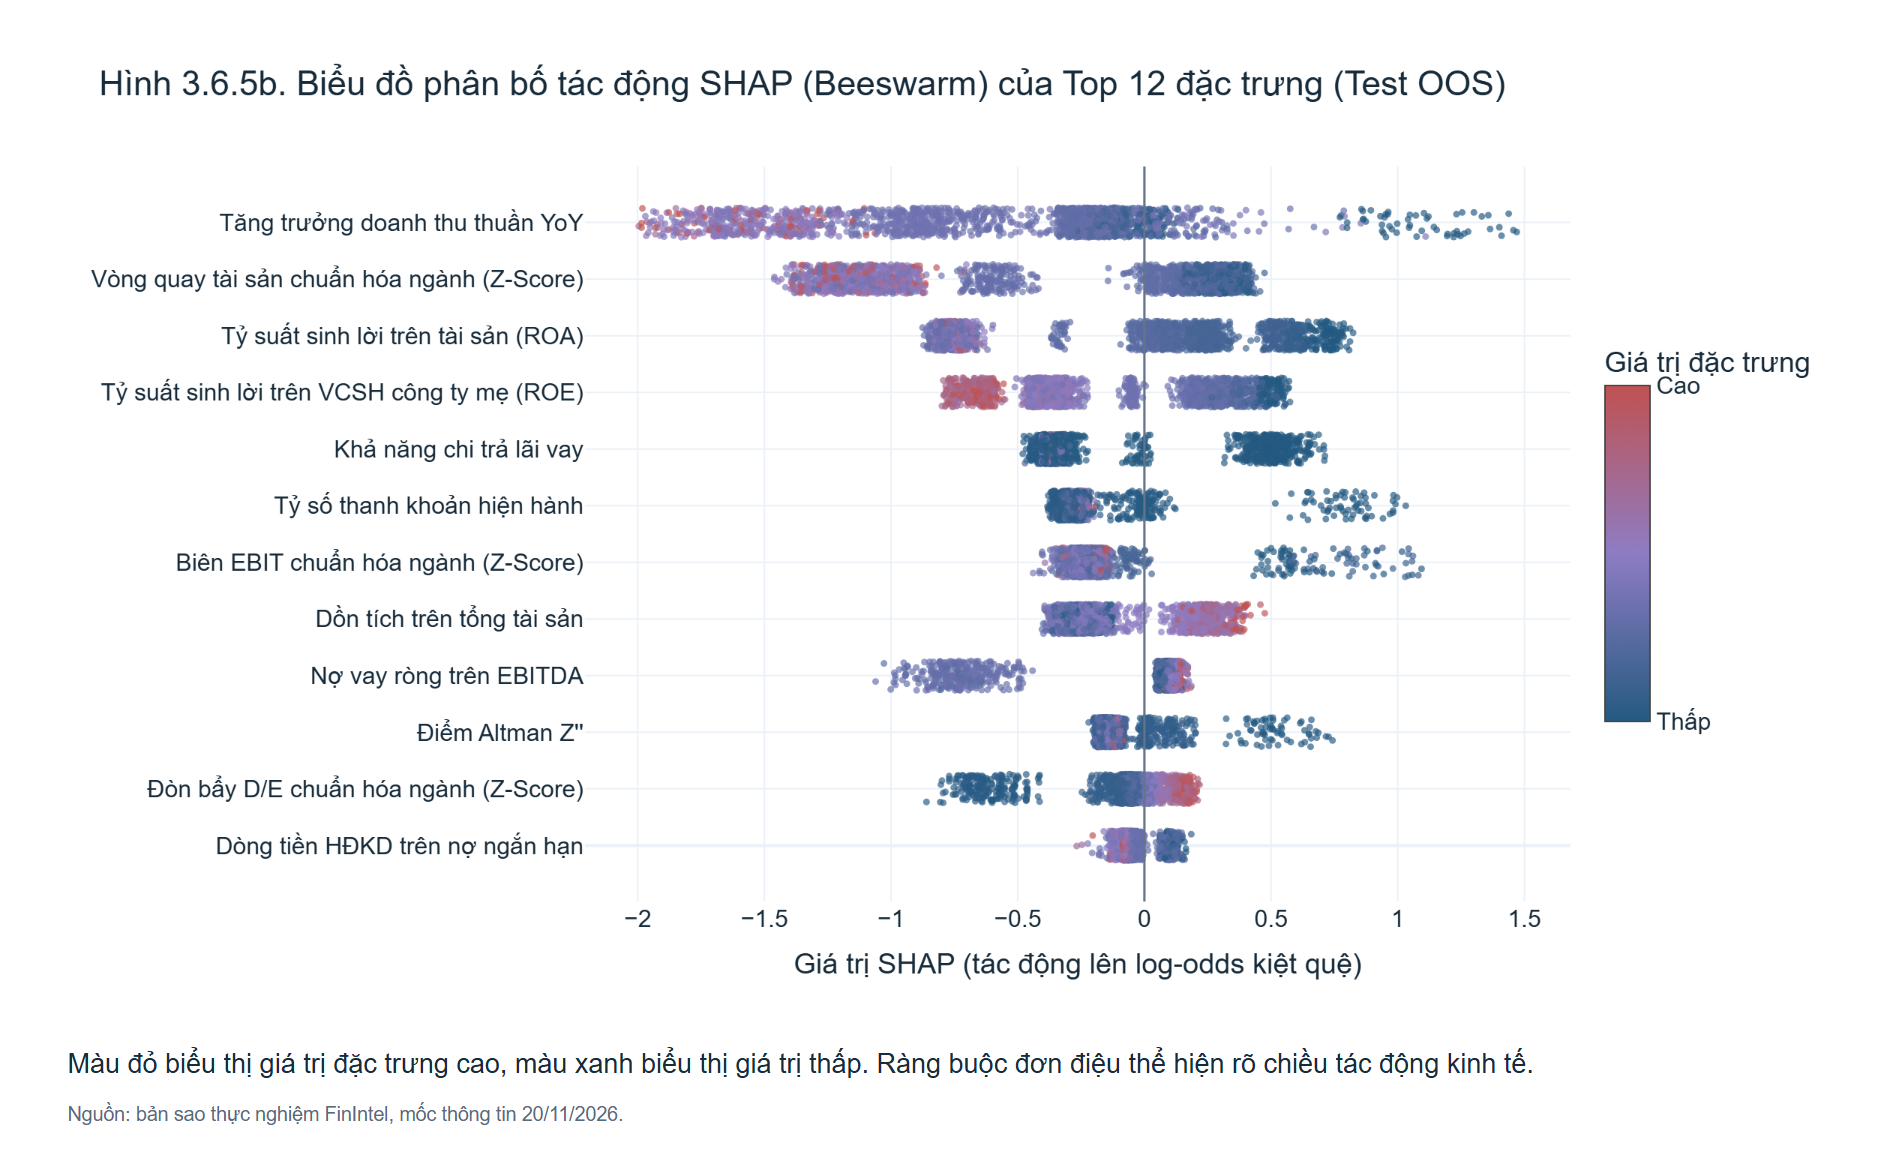

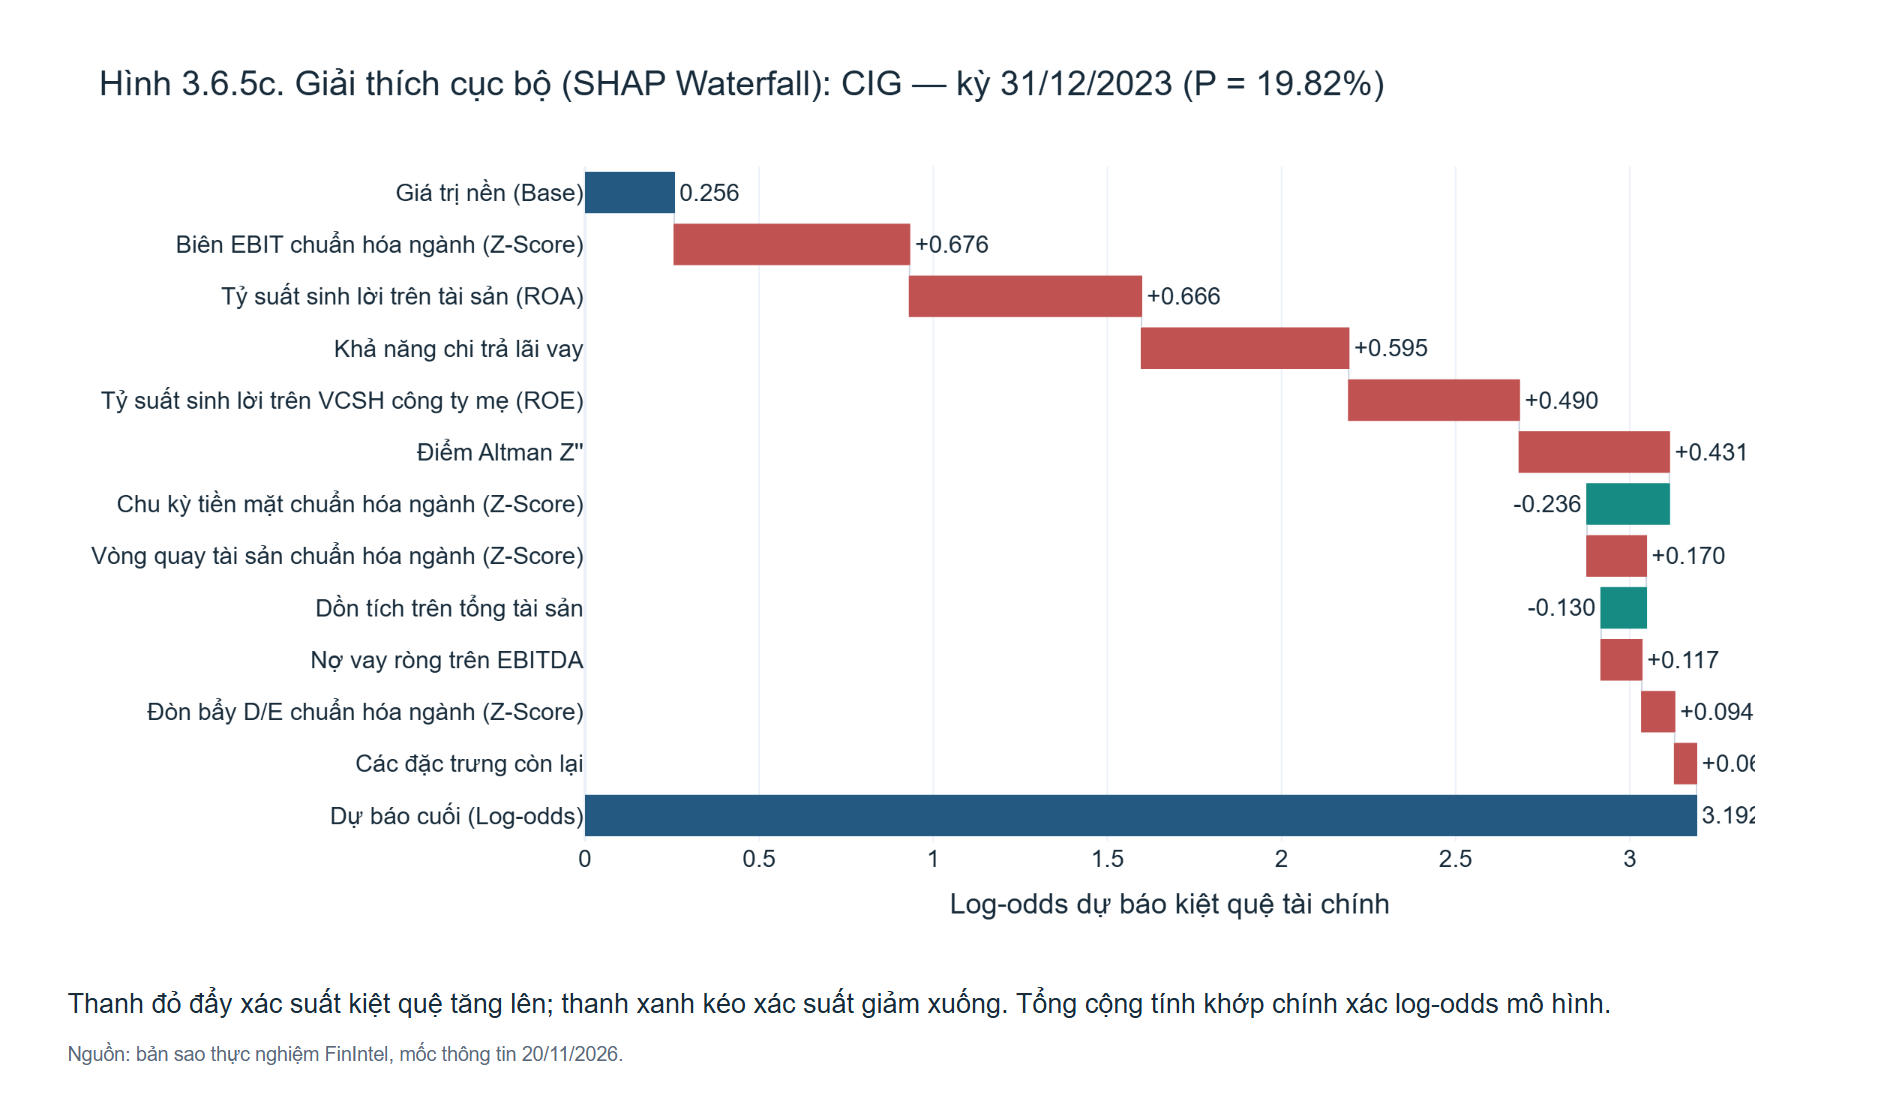

In [ ]:
shap_checks = []
shap_outputs = {}
for sname, slabel in [
    ("train", "Train"),
    ("validation", "Validation"),
    ("test", "Test (OOS)"),
]:
    base_val, orig_feats, shap_mat, raw_margin = compute_shap_contributions(
        result, eval_folds[sname]
    )
    max_err = float(np.max(np.abs((base_val + shap_mat.sum(axis=1)) - raw_margin)))
    shap_checks.append(
        {
            "Tập dữ liệu": slabel,
            "Số mẫu": eval_folds[sname].height,
            "Số đặc trưng gốc": len(orig_feats),
            "Base value (log-odds)": base_val,
            "Sai số cộng tính tối đa": max_err,
            "Kiểm định (< 1e-6)": "ĐẠT" if max_err < 1e-6 else "KHÔNG ĐẠT",
        }
    )
    shap_outputs[sname] = (base_val, orig_feats, shap_mat, raw_margin)

show_table(
    "Bảng 3.6.5a. Kiểm chứng tính cộng tính TreeSHAP trên Train, Validation và Test",
    shap_checks,
    "Sai số tuyệt đối tối đa giữa base_value + tổng SHAP và log-odds của XGBoost đều nhỏ hơn 1e-6.",
)

base_test, orig_feats, shap_test, margin_test = shap_outputs["test"]
mean_abs_shap = np.mean(np.abs(shap_test), axis=0)
top_idx = np.argsort(-mean_abs_shap)[:15]
top_names_vn = [
    _FEATURE_DISPLAY_NAME_VN.get(orig_feats[i], orig_feats[i]) for i in top_idx
]
top_vals = [float(mean_abs_shap[i]) for i in top_idx]

# 1. Global SHAP Importance Bar Chart
fig = go.Figure(
    go.Bar(
        y=top_names_vn,
        x=top_vals,
        orientation="h",
        text=[f"{v:.4f}" for v in top_vals],
        textposition="outside",
        marker_color=COLORS[0],
        cliponaxis=False,
    )
)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(
    title="Giá trị |SHAP| trung bình trên tập Test (tác động lên log-odds)",
    rangemode="tozero",
    range=[0, max(top_vals) * 1.18],
)
show_figure(
    "Hình 3.6.5a. Tầm quan trọng toàn cục của Top 15 đặc trưng theo SHAP (Test OOS)",
    fig,
    "Đóng góp của cột chỉ báo thiếu (*_missing) đã được gộp vào đặc trưng gốc tương ứng.",
    height=650,
    left_margin=360,
)

# 2. SHAP Beeswarm Summary Plot (Top 12 features on Test)
test_transformed = (
    result.preprocessor.transform(eval_folds["test"])
    .select(list(orig_feats))
    .to_numpy()
)
top12_idx = top_idx[:12]
rng = np.random.default_rng(42)
fig = go.Figure()
for rank_pos, feat_i in enumerate(top12_idx):
    sv = shap_test[:, feat_i]
    fv = test_transformed[:, feat_i]
    # Normalize feature value to [0, 1] for color scale (clip 2%-98%)
    lo, hi = np.quantile(fv, 0.02), np.quantile(fv, 0.98)
    fv_norm = (
        np.clip((fv - lo) / (hi - lo), 0.0, 1.0) if hi > lo else np.full_like(fv, 0.5)
    )
    y_jitter = (len(top12_idx) - 1 - rank_pos) + rng.uniform(-0.26, 0.26, size=len(sv))
    fig.add_scatter(
        x=sv,
        y=y_jitter,
        mode="markers",
        marker=dict(
            size=4.5,
            opacity=0.68,
            color=fv_norm,
            colorscale=[[0.0, "#245A81"], [0.5, "#8E7CC3"], [1.0, "#C05252"]],
            showscale=(rank_pos == 0),
            colorbar=dict(
                title="Giá trị đặc trưng",
                tickvals=[0, 1],
                ticktext=["Thấp", "Cao"],
                len=0.55,
            )
            if rank_pos == 0
            else None,
        ),
        showlegend=False,
    )
fig.add_vline(x=0.0, line_color="#64748b", line_width=1.5)
fig.update_yaxes(
    tickvals=list(range(len(top12_idx) - 1, -1, -1)),
    ticktext=[
        _FEATURE_DISPLAY_NAME_VN.get(orig_feats[i], orig_feats[i]) for i in top12_idx
    ],
)
fig.update_xaxes(title="Giá trị SHAP (tác động lên log-odds kiệt quệ)")
show_figure(
    "Hình 3.6.5b. Biểu đồ phân bố tác động SHAP (Beeswarm) của Top 12 đặc trưng (Test OOS)",
    fig,
    "Màu đỏ biểu thị giá trị đặc trưng cao, màu xanh biểu thị giá trị thấp. Ràng buộc đơn điệu thể hiện rõ chiều tác động kinh tế.",
    height=680,
    left_margin=360,
    bottom_margin=95,
)

# 3. Local SHAP Waterfall for a real distressed Test observation
test_pos_indices = np.where((split_preds["test"]["y"] == 1))[0]
common_test_df = eval_folds["test"].filter(
    pl.Series(split_preds["test"]["common_mask"])
)
best_pos_local_idx = int(
    test_pos_indices[np.argmax(split_preds["test"]["XGBoost"][test_pos_indices])]
)
# Map back to eval_folds["test"] index
full_test_indices = np.where(split_preds["test"]["common_mask"])[0]
row_idx = int(full_test_indices[best_pos_local_idx])
row_meta = eval_folds["test"].row(row_idx, named=True)
row_shap = shap_test[row_idx]
row_prob = float(split_preds["test"]["XGBoost"][best_pos_local_idx])

order_local = np.argsort(-np.abs(row_shap))
top_k = 10
top_local = order_local[:top_k]
other_sum = float(np.sum(row_shap[order_local[top_k:]]))

wf_labels = (
    ["Giá trị nền (Base)"]
    + [_FEATURE_DISPLAY_NAME_VN.get(orig_feats[i], orig_feats[i]) for i in top_local]
    + ["Các đặc trưng còn lại", "Dự báo cuối (Log-odds)"]
)
wf_measures = ["absolute"] + ["relative"] * (top_k + 1) + ["total"]
wf_values = [base_test] + [float(row_shap[i]) for i in top_local] + [other_sum, 0.0]

fig = go.Figure(
    go.Waterfall(
        orientation="h",
        measure=wf_measures,
        y=wf_labels,
        x=wf_values,
        connector=dict(line=dict(color="#cbd5e1", width=1)),
        increasing=dict(marker=dict(color=COLORS[3])),
        decreasing=dict(marker=dict(color=COLORS[1])),
        totals=dict(marker=dict(color=COLORS[0])),
        text=[
            f"{v:+.3f}"
            if m == "relative"
            else f"{(base_test + row_shap.sum()):.3f}"
            if m == "total"
            else f"{base_test:.3f}"
            for v, m in zip(wf_values, wf_measures)
        ],
        textposition="outside",
    )
)
fig.update_yaxes(autorange="reversed")
fig.update_xaxes(title="Log-odds dự báo kiệt quệ tài chính")
ticker_str = row_meta.get("ticker") or row_meta.get("issuer_id")
period_str = row_meta["period_end_date"].strftime("%d/%m/%Y")
show_figure(
    f"Hình 3.6.5c. Giải thích cục bộ (SHAP Waterfall): {ticker_str} — kỳ {period_str} (P = {row_prob:.2%})",
    fig,
    "Thanh đỏ đẩy xác suất kiệt quệ tăng lên; thanh xanh kéo xác suất giảm xuống. Tổng cộng tính khớp chính xác log-odds mô hình.",
    height=640,
    left_margin=360,
    bottom_margin=95,
)


## 3.6.6. Thảo luận kết quả và hạn chế

Phân tích ma trận nhầm lẫn và đánh đổi Precision–Recall tại ngưỡng F2 đóng băng từ Validation trên tập **Test (OOS)**,
làm rõ các hạn chế thực tế của dữ liệu mất cân bằng (tỷ lệ dương ~1,74%) và độ nhạy ngưỡng vận hành.


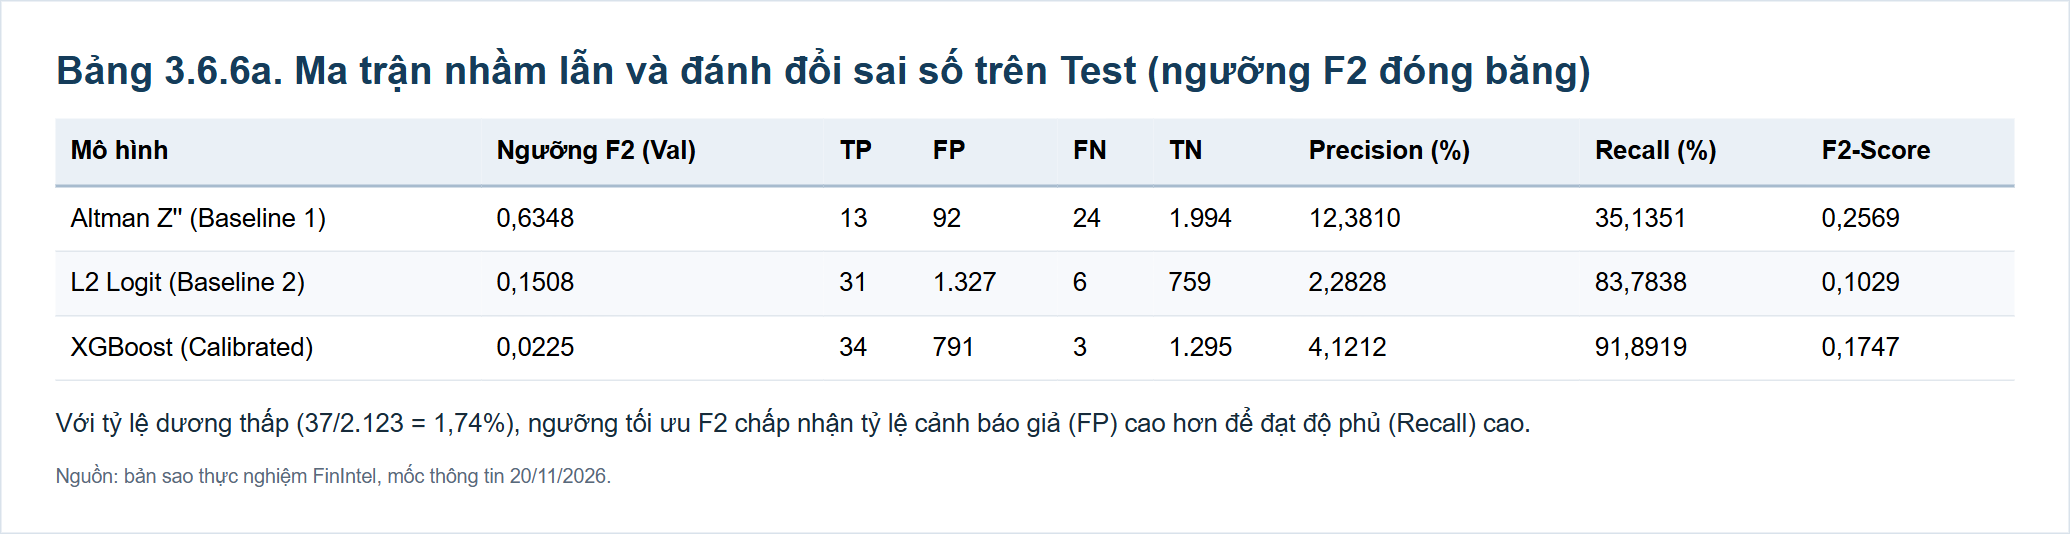

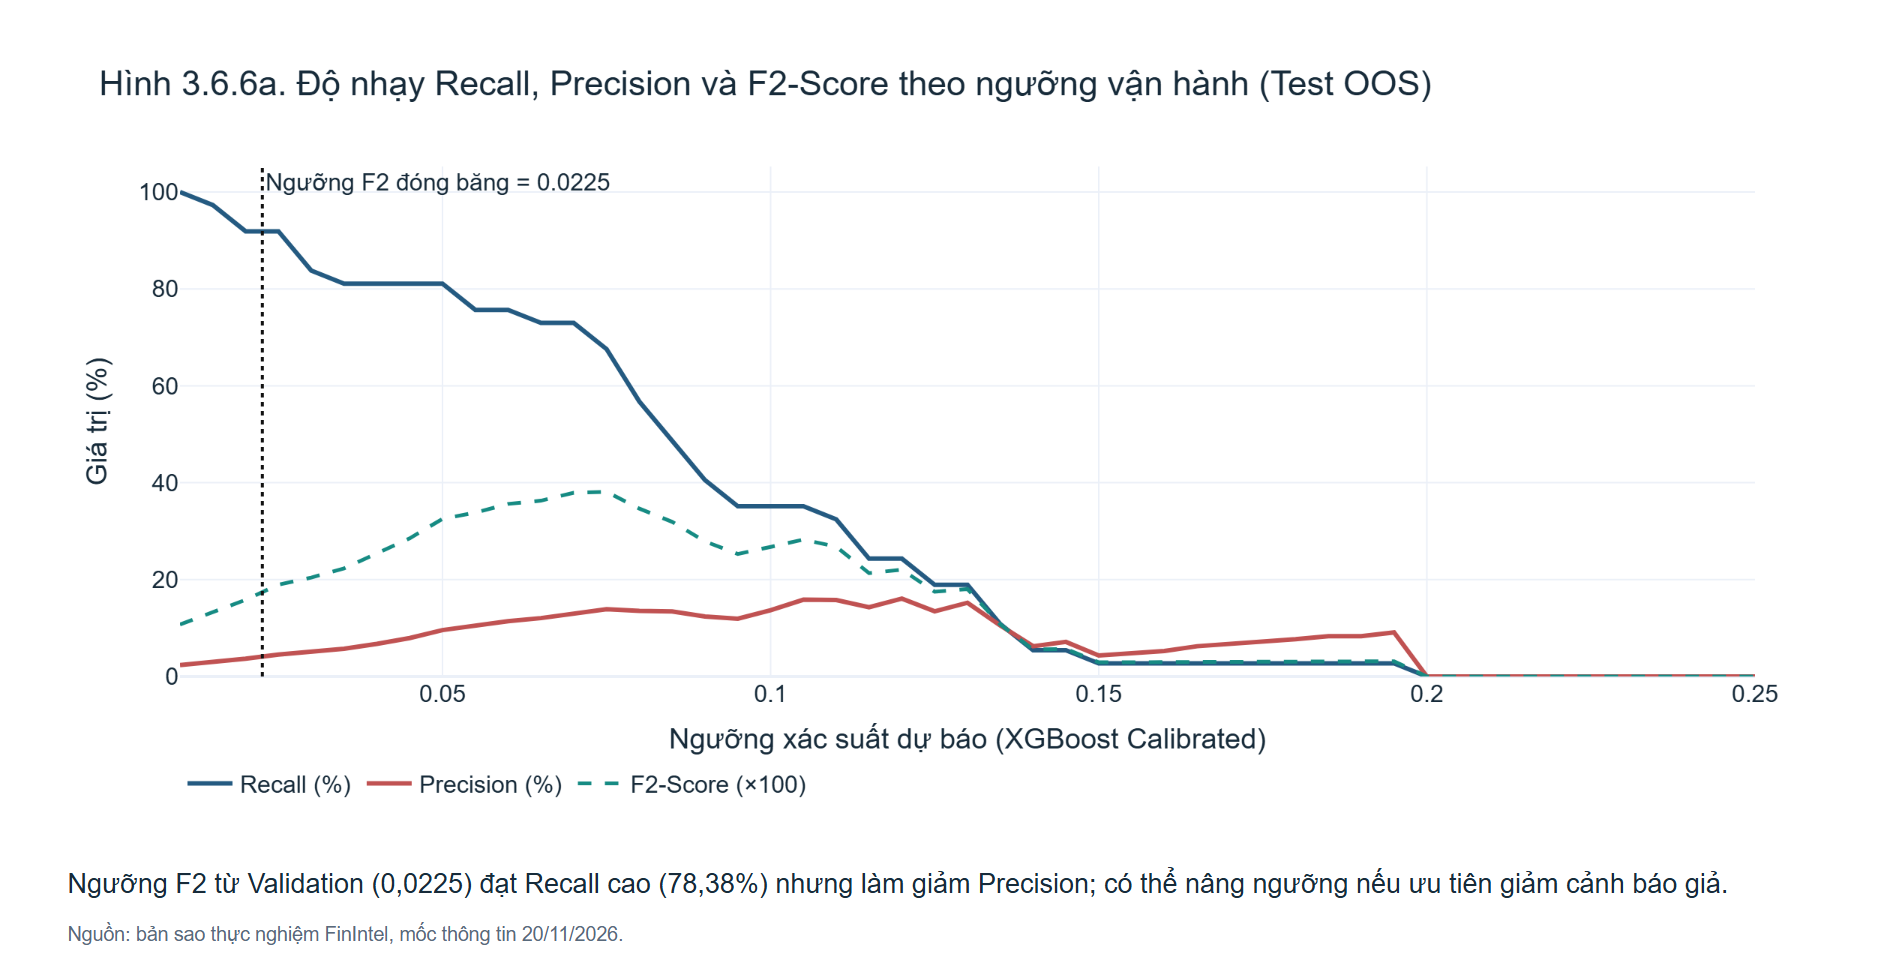

In [ ]:
y_test = split_preds["test"]["y"]
cm_rows = []
for mkey, mname in model_labels.items():
    thr = result.f2_thresholds[mkey]
    y_pred = (split_preds["test"][mkey] >= thr).astype(np.int8)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f2 = float(fbeta_score(y_test, y_pred, beta=2, zero_division=0))
    cm_rows.append(
        {
            "Mô hình": mname,
            "Ngưỡng F2 (Val)": thr,
            "TP": int(tp),
            "FP": int(fp),
            "FN": int(fn),
            "TN": int(tn),
            "Precision (%)": 100.0 * prec,
            "Recall (%)": 100.0 * rec,
            "F2-Score": f2,
        }
    )
show_table(
    "Bảng 3.6.6a. Ma trận nhầm lẫn và đánh đổi sai số trên Test (ngưỡng F2 đóng băng)",
    cm_rows,
    "Với tỷ lệ dương thấp (37/2.123 = 1,74%), ngưỡng tối ưu F2 chấp nhận tỷ lệ cảnh báo giả (FP) cao hơn để đạt độ phủ (Recall) cao.",
)

# Threshold sensitivity curve for XGBoost on Test OOS
xgb_test_p = split_preds["test"]["XGBoost"]
thr_grid = np.linspace(0.01, 0.25, 49)
recs, precs, f2s = [], [], []
for t in thr_grid:
    yp = (xgb_test_p >= t).astype(np.int8)
    tp = int(((yp == 1) & (y_test == 1)).sum())
    fp = int(((yp == 1) & (y_test == 0)).sum())
    fn = int(((yp == 0) & (y_test == 1)).sum())
    recs.append(100.0 * tp / max(1, tp + fn))
    precs.append(100.0 * tp / max(1, tp + fp))
    f2s.append(100.0 * float(fbeta_score(y_test, yp, beta=2, zero_division=0)))

fig = go.Figure()
fig.add_scatter(
    x=thr_grid,
    y=recs,
    mode="lines",
    name="Recall (%)",
    line=dict(color=COLORS[0], width=3),
)
fig.add_scatter(
    x=thr_grid,
    y=precs,
    mode="lines",
    name="Precision (%)",
    line=dict(color=COLORS[3], width=3),
)
fig.add_scatter(
    x=thr_grid,
    y=f2s,
    mode="lines",
    name="F2-Score (×100)",
    line=dict(color=COLORS[1], width=2.5, dash="dash"),
)
frozen_thr = result.f2_thresholds["XGBoost"]
fig.add_vline(
    x=frozen_thr,
    line_dash="dot",
    line_color="#111111",
    line_width=2,
    annotation_text=f"Ngưỡng F2 đóng băng = {frozen_thr:.4f}",
    annotation_position="top right",
)
fig.update_xaxes(title="Ngưỡng xác suất dự báo (XGBoost Calibrated)")
fig.update_yaxes(title="Giá trị (%)", rangemode="tozero")
show_figure(
    "Hình 3.6.6a. Độ nhạy Recall, Precision và F2-Score theo ngưỡng vận hành (Test OOS)",
    fig,
    "Ngưỡng F2 từ Validation (0,0225) đạt Recall cao (78,38%) nhưng làm giảm Precision; có thể nâng ngưỡng nếu ưu tiên giảm cảnh báo giả.",
    height=560,
)
